# Reconocimiento de Lengua de Señas Colombiana — LSC-54

**Inteligencia Artificial II · Proyecto final**

Nicolas Echeverri Rueda · Joseph Felipe Rodriguez · Julian Delgado Guerrero

El objetivo es identificar cuál de **54 señas** de LSC aparece en un video: 11 colores,
10 números y 33 expresiones de cortesía. Cada video se convierte con MediaPipe en una
secuencia de coordenadas del cuerpo y las manos, y un modelo decide qué seña es.

Probamos dos arquitecturas:

- **Transformer de signjoey** (Camgöz et al., CVPR 2020), entrenado desde cero.
- **SL-TSSI-DenseNet** (Laines et al., CVPRW 2023), que convierte la secuencia en una
  imagen y la clasifica con una CNN preentrenada en ImageNet.

Al mejor de los dos le aplicamos después **aumento de datos** para reducir el sobreajuste.

La evaluación siempre se hace con **personas que el modelo nunca vio**.

## Cómo ejecutar este cuaderno

Se ejecuta de arriba abajo. **No repite nada que ya esté guardado en disco**: cada etapa
revisa si su resultado existe y, si está, lo carga. Si se borra una carpeta, esa etapa
se vuelve a ejecutar sola, y entonces sí tarda.

| Etapa | Qué revisa | Si falta |
|---|---|---|
| Extracción con MediaPipe | `dataset_completo/lsc.all` | ~1 h (necesita `Data/RawVideos`) |
| LSTM de diagnóstico | `modelos/lstm/*.pt` | ~3,5 h |
| Transformer | `modelos/lsc_full`, `modelos/lsc_norm` | ~5 h cada uno |
| SL-TSSI-DenseNet | `modelos/sl_tssi_v2/best.pt` | ~2 h |
| SL-TSSI-DenseNet con aumento | `modelos/sl_tssi_aug/best.pt` | ~3 h |


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import gzip, json, pickle, sys, time

import numpy as np
import torch
import matplotlib.pyplot as plt

# Raíz del proyecto: la carpeta que contiene lsc_pipeline.py.
ROOT = Path.cwd()
if not (ROOT / "lsc_pipeline.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import lsc_pipeline as lp

DATOS = ROOT / "dataset_completo"
MODELOS = ROOT / "modelos"

AZUL, NARANJA, VERDE = "#4C72B0", "#DD8452", "#55A868"

print("Proyecto en:", ROOT, "\n")
print("OK     torch", torch.__version__)

for ruta in (DATOS / "lsc.test",
             MODELOS / "lsc_full" / "best.ckpt",
             MODELOS / "lsc_norm" / "best.ckpt",
             MODELOS / "sl_tssi_v2" / "best.pt",
             MODELOS / "sl_tssi_aug" / "best.pt"):
    marca = "OK    " if ruta.is_file() else "FALTA "
    print(f"{marca} {ruta.relative_to(ROOT).as_posix()}")

print("\nLo que diga FALTA se vuelve a generar al llegar a su sección.")

Proyecto en: C:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador 

OK     torch 2.15.0+cpu
OK     dataset_completo/lsc.test
OK     modelos/lsc_full/best.ckpt
OK     modelos/lsc_norm/best.ckpt
OK     modelos/sl_tssi_v2/best.pt
OK     modelos/sl_tssi_aug/best.pt

Lo que diga FALTA se vuelve a generar al llegar a su sección.


---
# 1. El dataset y las características

LSC-54 son 2.880 videos de 34 personas grabando 54 señas. Los archivos están
organizados por carpetas, y el nombre de la carpeta de la seña es la etiqueta:

```
Videos <Categoría>/<Señalante>/<Categoría>/<Seña>/<n>.avi
```

El modelo no recibe píxeles. MediaPipe detecta en cada fotograma 33 puntos del cuerpo y
21 de cada mano; con sus coordenadas `x`, `y`, `z` eso da **225 números por fotograma**
(99 + 63 + 63). Cuando no detecta una mano, esos 63 valores quedan en cero.

La extracción se hace una sola vez y se guarda en `dataset_completo/`. Tardó **62 minutos**
con 4 procesos en paralelo.

En el conteo por carpeta, `Courtesy` aparece con 43 señas: el señalante 34 tiene sus
10 números también dentro de la carpeta de cortesía (30 videos). Para agrupar por
categoría, una seña que está en las dos carpetas se cuenta como número, así que las 54
señas quedan en 11 colores, 33 de cortesía y 10 números.

In [2]:
RECONSTRUIR = False        # True obliga a extraer todo otra vez (~1 h)

ruta_all = DATOS / "lsc.all"
if ruta_all.is_file() and not RECONSTRUIR:
    print(f"Características ya extraídas: {ruta_all.relative_to(ROOT).as_posix()}\n")
else:
    videos = lp.scan_videos()
    print(f"Extrayendo características de {len(videos):,} videos...")
    lp.build_dataset(videos, workers=4, force=RECONSTRUIR)

manifest = json.loads((DATOS / "manifest.json").read_text(encoding="utf-8"))

# Una misma seña puede estar en dos carpetas: los números del señalante 34 están dentro
# de Cordialidad y de Numeros a la vez. Esto se usa después para agrupar por categoría.
categorias_por_glosa = defaultdict(set)
for e in manifest:
    categorias_por_glosa[e["gloss"]].add(e["category"])

print(f"Videos:     {len(manifest):,}")
print(f"Señalantes: {len({e['signer'] for e in manifest})}")
print(f"Señas:      {len({e['gloss'] for e in manifest})}")
print()
for cat in sorted({e["category"] for e in manifest}):
    de_cat = [e for e in manifest if e["category"] == cat]
    print(f"  {cat:<12} {len(de_cat):>5} videos   {len({e['gloss'] for e in de_cat}):>2} señas")

Características ya extraídas: dataset_completo/lsc.all

Videos:     2,880
Señalantes: 34
Señas:      54

  Colors        1110 videos   11 señas
  Courtesy      1228 videos   43 señas
  Numbers        542 videos   10 señas


## División 60/20/20 por señalante

La división se hace **por persona**, no por video: todos los videos de un señalante caen
en el mismo conjunto. Si se dividiera al azar, el modelo vería en prueba a gente que ya
vio entrenando y el resultado estaría inflado.

20 personas para entrenar, 7 para validar y 7 para probar.

In [3]:
if not all((DATOS / f"lsc.{n}").is_file() for n in ("train", "dev", "test")):
    lp.split_dataset(lp.load_gzip_pickle(ruta_all))
    print()


def cargar_split(nombre):
    with gzip.open(DATOS / f"lsc.{nombre}", "rb") as f:
        return pickle.load(f)


train_raw, dev_raw, test_raw = cargar_split("train"), cargar_split("dev"), cargar_split("test")
total = len(train_raw) + len(dev_raw) + len(test_raw)

for nombre, parte in (("train", train_raw), ("dev", dev_raw), ("test", test_raw)):
    print(f"{nombre:5s}: {len(parte):4d} videos ({len(parte) / total:6.2%})  "
          f"{len({e['signer'] for e in parte})} señalantes  "
          f"{len({e['gloss'] for e in parte})} señas")

assert not (lp.TRAIN_SIGNERS & lp.VAL_SIGNERS)
assert not (lp.TRAIN_SIGNERS & lp.TEST_SIGNERS)
assert not (lp.VAL_SIGNERS & lp.TEST_SIGNERS)
print("\nSplit por señalante verificado: no hay solapamiento.")

CLASES = sorted({e["gloss"] for e in train_raw})
A_INDICE = {g: i for i, g in enumerate(CLASES)}
T_MAX = max(e["sign"].shape[0] for e in train_raw + dev_raw + test_raw)

# Cada seña pertenece a una de tres categorías.
grupo = {g: ("Números" if len(c) > 1 else "Colores" if "Colors" in c else "Cortesía")
         for g, c in categorias_por_glosa.items()}

train: 1733 videos (60.17%)  20 señalantes  54 señas
dev  :  579 videos (20.10%)  7 señalantes  54 señas
test :  568 videos (19.72%)  7 señalantes  54 señas

Split por señalante verificado: no hay solapamiento.


Números por fotograma: 225
Duración: de 16 a 335 fotogramas
Las más frecuentes: 30 (1129 videos), 40 (42 videos), 45 (40 videos), 42 (38 videos)
Clases: 54


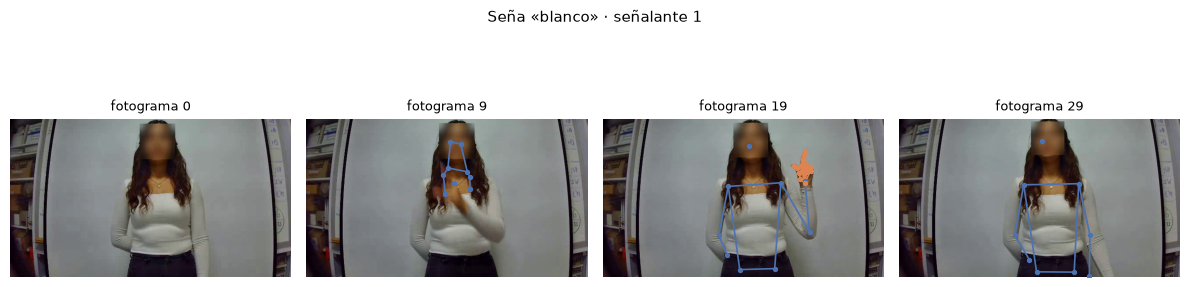

In [4]:
longitudes = Counter(e["sign"].shape[0] for e in train_raw + dev_raw + test_raw)

print(f"Números por fotograma: {train_raw[0]['sign'].shape[1]}")
print(f"Duración: de {min(longitudes)} a {T_MAX} fotogramas")
print("Las más frecuentes:", ", ".join(f"{t} ({n} videos)" for t, n in longitudes.most_common(4)))
print(f"Clases: {len(CLASES)}")

# --- Cómo se ve lo que recibe el modelo ---
CONEX_POSE = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24)]
CONEX_MANO = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8),
              (0, 9), (9, 10), (10, 11), (11, 12), (0, 13), (13, 14), (14, 15), (15, 16),
              (0, 17), (17, 18), (18, 19), (19, 20), (5, 9), (9, 13), (13, 17)]
PUNTOS_POSE = [0, 11, 12, 13, 14, 15, 16, 23, 24]   # nariz, hombros, codos, muñecas, caderas


def leer_fotograma(nombre, t):
    """Lee el fotograma t del video original (en RGB), o None si no se puede."""
    import cv2
    cap = cv2.VideoCapture(str(lp.RAW / nombre))
    for _ in range(int(t) + 1):
        ok, imagen = cap.read()
    cap.release()
    return cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB) if ok else None


def dibujar_esqueleto(ax, fila, fondo=None):
    """Dibuja un fotograma a partir de sus 225 números."""
    pose = fila[0:99].reshape(33, 3)
    izquierda = fila[99:162].reshape(21, 3)
    derecha = fila[162:225].reshape(21, 3)

    if fondo is not None:
        ax.imshow(fondo, extent=(0, 1, 1, 0), zorder=1)

    for puntos, conexiones, usados, color in (
            (pose, CONEX_POSE, PUNTOS_POSE, AZUL),
            (izquierda, CONEX_MANO, range(21), NARANJA),
            (derecha, CONEX_MANO, range(21), VERDE)):
        if not puntos.any():
            continue
        for a, b in conexiones:
            ax.plot([puntos[a, 0], puntos[b, 0]], [puntos[a, 1], puntos[b, 1]],
                    color=color, lw=1.2, zorder=2)
        ax.scatter(puntos[list(usados), 0], puntos[list(usados), 1],
                   s=8, color=color, zorder=3)
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)
    ax.set_aspect("equal" if fondo is None else fondo.shape[0] / fondo.shape[1])
    ax.axis("off")


ejemplo = train_raw[12]
momentos = np.linspace(0, ejemplo["sign"].shape[0] - 1, 4).astype(int)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for ax, t in zip(axes, momentos):
    dibujar_esqueleto(ax, ejemplo["sign"][t].numpy(), fondo=leer_fotograma(ejemplo["name"], t))
    ax.set_title(f"fotograma {t}", fontsize=9)
fig.suptitle(f"Seña «{ejemplo['gloss']}» · señalante {ejemplo['signer']}", fontsize=11)
plt.tight_layout()
plt.show()

---
# 2. Normalización de las coordenadas

MediaPipe entrega las coordenadas **respecto a la imagen**. Eso quiere decir que si la
persona está más cerca de la cámara, o más a la izquierda, los mismos dedos dan números
distintos. Para señas que se diferencian solo en la configuración de la mano (los
números, sobre todo) esa información queda enterrada.

La normalización arregla dos cosas:

| Parte | Antes | Después |
|---|---|---|
| Cuerpo | Coordenadas de la imagen | Centrado entre los hombros, escalado por su separación |
| Cada mano | Coordenadas de la imagen | Centrada en su propia muñeca, escalada por el tamaño de la mano |

La posición de las manos no se pierde: sigue estando en los puntos 15 y 16 de la pose.
Lo que se añade es la **forma** de la mano, independiente de dónde esté.

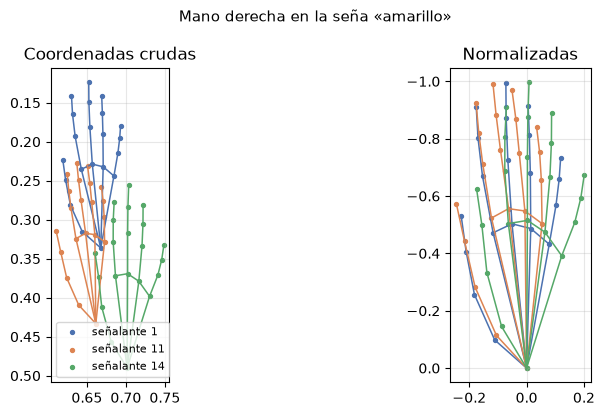

Crudas, las tres manos caen en sitios y tamaños distintos.
Normalizadas se superponen: queda la forma, que es lo que distingue una seña.


In [5]:
def normalizar(secuencia):
    """Centra el cuerpo entre los hombros y cada mano en su propia muñeca."""
    s = secuencia.clone()
    pose = s[:, 0:99].reshape(-1, 33, 3)
    izquierda = s[:, 99:162].reshape(-1, 21, 3)
    derecha = s[:, 162:225].reshape(-1, 21, 3)

    # Cuerpo: los puntos 11 y 12 de MediaPipe son los hombros.
    hombro_izq, hombro_der = pose[:, 11, :], pose[:, 12, :]
    centro = ((hombro_izq + hombro_der) / 2).unsqueeze(1)
    ancho = torch.norm(hombro_izq[:, :2] - hombro_der[:, :2], dim=1)
    ancho = torch.clamp(ancho, min=1e-3).view(-1, 1, 1)
    hay_pose = (pose.abs().sum(dim=(1, 2)) > 0).view(-1, 1, 1)
    pose = torch.where(hay_pose, (pose - centro) / ancho, pose)

    def normalizar_mano(mano):
        hay_mano = (mano.abs().sum(dim=(1, 2)) > 0).view(-1, 1, 1)
        centrada = mano - mano[:, 0:1, :]                   # muñeca al origen
        escala = centrada.norm(dim=2).max(dim=1).values
        escala = torch.clamp(escala, min=1e-3).view(-1, 1, 1)
        return torch.where(hay_mano, centrada / escala, mano)

    izquierda = normalizar_mano(izquierda)
    derecha = normalizar_mano(derecha)
    return torch.cat(
        [pose.reshape(-1, 99), izquierda.reshape(-1, 63), derecha.reshape(-1, 63)],
        dim=1,
    )


# La misma seña hecha por tres personas distintas.
GLOSA_DEMO = "amarillo"
muestras, vistos = [], set()
for e in train_raw:
    if e["gloss"] != GLOSA_DEMO or e["signer"] in vistos:
        continue
    con_mano = [t for t in range(e["sign"].shape[0]) if e["sign"][t, 162:225].abs().sum() > 0]
    if con_mano:
        vistos.add(e["signer"])
        muestras.append((e, con_mano[len(con_mano) // 2]))
    if len(muestras) == 3:
        break

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
for (e, t), color in zip(muestras, (AZUL, NARANJA, VERDE)):
    cruda = e["sign"][t, 162:225].reshape(21, 3).numpy()
    norm = normalizar(e["sign"].float())[t, 162:225].reshape(21, 3).numpy()
    for ax, puntos in ((ax1, cruda), (ax2, norm)):
        for a, b in CONEX_MANO:
            ax.plot([puntos[a, 0], puntos[b, 0]], [puntos[a, 1], puntos[b, 1]],
                    color=color, lw=1.1)
        ax.scatter(puntos[:, 0], puntos[:, 1], s=8, color=color,
                   label=f"señalante {e['signer']}")

for ax, titulo in ((ax1, "Coordenadas crudas"), (ax2, "Normalizadas")):
    ax.set_title(titulo)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.grid(alpha=0.3)
ax1.legend(fontsize=8)
fig.suptitle(f"Mano derecha en la seña «{GLOSA_DEMO}»", fontsize=11)
plt.tight_layout()
plt.show()

print("Crudas, las tres manos caen en sitios y tamaños distintos.")
print("Normalizadas se superponen: queda la forma, que es lo que distingue una seña.")

## ¿Sirve de verdad? Prueba rápida con una LSTM

Antes de reentrenar el Transformer (5 horas) comprobamos la idea con un modelo pequeño:
una LSTM de tres capas, entrenada **dos veces** con exactamente los mismos datos, la
misma semilla y las mismas épocas. Lo único que cambia es si las características están
normalizadas o no. Cualquier diferencia es atribuible a la normalización.

In [6]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


def a_tensores(datos, transformar=None):
    """Rellena hasta T_MAX y devuelve datos, longitudes reales y etiquetas."""
    X = torch.zeros(len(datos), T_MAX, 225)
    L = torch.zeros(len(datos), dtype=torch.long)
    y = torch.zeros(len(datos), dtype=torch.long)
    for i, ejemplo in enumerate(datos):
        secuencia = ejemplo["sign"].float()
        if transformar is not None:
            secuencia = transformar(secuencia)
        X[i, : secuencia.shape[0]] = secuencia
        L[i] = secuencia.shape[0]
        y[i] = A_INDICE[ejemplo["gloss"]]
    return X, L, y


class ClasificadorLSTM(nn.Module):
    def __init__(self, n_clases, dim_entrada=225):
        super().__init__()
        self.lstm1 = nn.LSTM(dim_entrada, 256, batch_first=True)
        self.lstm2 = nn.LSTM(256, 128, batch_first=True)
        self.lstm3 = nn.LSTM(128, 64, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.densas = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_clases))

    def forward(self, x, longitudes):
        x, _ = self.lstm1(x); x = torch.relu(x)
        x, _ = self.lstm2(x); x = torch.relu(x)
        x, _ = self.lstm3(x)
        # Promediar solo los fotogramas reales, ignorando el relleno.
        pasos = torch.arange(x.shape[1], device=x.device)[None, :]
        mascara = (pasos < longitudes[:, None]).float().unsqueeze(-1)
        x = (x * mascara).sum(1) / mascara.sum(1)
        return self.densas(self.dropout(x))


def entrenar_lstm(transformar, etiqueta, ruta, epocas=120, semilla=42):
    torch.manual_seed(semilla)
    Xtr, Ltr, ytr = a_tensores(train_raw, transformar)
    Xdv, Ldv, ydv = a_tensores(dev_raw, transformar)

    modelo = ClasificadorLSTM(len(CLASES))
    optim = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    criterio = nn.CrossEntropyLoss()
    cargador = DataLoader(TensorDataset(Xtr, Ltr, ytr), batch_size=32, shuffle=True)

    mejor, mejores_pesos, historial = 0.0, None, []
    for epoca in range(1, epocas + 1):
        modelo.train()
        for xb, lb, yb in cargador:
            optim.zero_grad()
            criterio(modelo(xb, lb), yb).backward()
            optim.step()
        modelo.eval()
        with torch.no_grad():
            acc = (modelo(Xdv, Ldv).argmax(1) == ydv).float().mean().item()
        if acc > mejor:
            mejor, mejores_pesos = acc, {k: v.clone() for k, v in modelo.state_dict().items()}
        if epoca % 20 == 0:
            print(f"  época {epoca:3d}  dev {acc:.1%}")
            historial.append((epoca, acc))

    ruta.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"model_state": mejores_pesos, "clases": CLASES,
                "mejor_dev": mejor, "historial": historial}, ruta)
    return mejores_pesos, mejor, historial


def probar_lstm(transformar, etiqueta, ruta):
    """Entrena si hace falta, y devuelve las predicciones de prueba."""
    if ruta.is_file():
        guardado = torch.load(ruta, map_location="cpu")
        assert guardado["clases"] == CLASES, "Las clases del modelo guardado no coinciden"
        pesos, mejor, historial = guardado["model_state"], guardado["mejor_dev"], guardado["historial"]
        print(f"  (ya entrenado, cargado desde {ruta.name})")
        for epoca, acc in historial:
            print(f"  época {epoca:3d}  dev {acc:.1%}")
    else:
        pesos, mejor, historial = entrenar_lstm(transformar, etiqueta, ruta)

    modelo = ClasificadorLSTM(len(CLASES))
    modelo.load_state_dict(pesos)
    modelo.eval()
    Xte, Lte, yte = a_tensores(test_raw, transformar)
    with torch.no_grad():
        predicciones = modelo(Xte, Lte).argmax(1)
    acc_test = (predicciones == yte).float().mean().item()
    print(f"{etiqueta}: mejor dev {mejor:.1%} | test {acc_test:.1%}\n")
    return predicciones, acc_test


DIR_LSTM = MODELOS / "lstm"
print("=== 1) CARACTERÍSTICAS CRUDAS ===")
pred_crudas, acc_crudas = probar_lstm(None, "CRUDAS", DIR_LSTM / "lstm_crudas.pt")
print("=== 2) CARACTERÍSTICAS NORMALIZADAS ===")
pred_norm, acc_norm = probar_lstm(normalizar, "NORMALIZADAS", DIR_LSTM / "lstm_normalizadas.pt")

=== 1) CARACTERÍSTICAS CRUDAS ===
  época  20  dev 6.4%
  época  40  dev 16.8%
  época  60  dev 20.9%
  época  80  dev 22.5%
  época 100  dev 25.9%
  época 120  dev 26.9%
CRUDAS: mejor dev 29.4% | test 25.4%

=== 2) CARACTERÍSTICAS NORMALIZADAS ===
  época  20  dev 18.1%
  época  40  dev 31.4%
  época  60  dev 45.3%
  época  80  dev 48.2%
  época 100  dev 50.1%
  época 120  dev 51.3%
NORMALIZADAS: mejor dev 54.2% | test 50.0%



In [7]:
# ¿Dónde se ganó? Desglose por categoría.
_, _, y_test = a_tensores(test_raw)


def desglose(predicciones):
    cat, glo = defaultdict(lambda: [0, 0]), defaultdict(lambda: [0, 0])
    for ejemplo, real, pred in zip(test_raw, y_test.tolist(), predicciones.tolist()):
        acierto = int(real == pred)
        c = grupo[ejemplo["gloss"]]
        cat[c][0] += acierto; cat[c][1] += 1
        glo[ejemplo["gloss"]][0] += acierto; glo[ejemplo["gloss"]][1] += 1
    return cat, glo


cat_c, _ = desglose(pred_crudas)
cat_l, _ = desglose(pred_norm)

print(f"{'CATEGORÍA':<14} {'crudas':>9} {'normaliz.':>10} {'cambio':>9}")
print("-" * 44)
for c in ("Colores", "Cortesía", "Números"):
    a, b = cat_c[c][0] / cat_c[c][1], cat_l[c][0] / cat_l[c][1]
    print(f"{c:<14} {a:>8.1%} {b:>10.1%} {b - a:>+8.1%}")
print(f"{'GLOBAL':<14} {acc_crudas:>8.1%} {acc_norm:>10.1%} {acc_norm - acc_crudas:>+8.1%}")

gana_mas = max(("Colores", "Cortesía", "Números"),
               key=lambda c: cat_l[c][0] / cat_l[c][1] - cat_c[c][0] / cat_c[c][1])
print(f"\nLas tres categorías mejoran; la que más gana es {gana_mas}.")
print("Con esto decidimos normalizar también los datos del Transformer.")

CATEGORÍA         crudas  normaliz.    cambio
--------------------------------------------
Colores           61.7%      83.3%   +21.7%
Cortesía          19.5%      48.1%   +28.6%
Números            7.9%      27.2%   +19.2%
GLOBAL            25.4%      50.0%   +24.6%

Las tres categorías mejoran; la que más gana es Cortesía.
Con esto decidimos normalizar también los datos del Transformer.


---
# 3. Primer enfoque: Transformer de signjoey

`signjoey` es el repositorio del artículo *Sign Language Transformers* (Camgöz et al.,
CVPR 2020). Es un encoder-decoder de 22,3 millones de parámetros que lee la secuencia de
coordenadas, reconoce las glosas con CTC y además traduce a texto.

Dos cosas que conviene decir de entrada:

- **Los pesos empiezan siendo aleatorios.** Los autores no publicaron un checkpoint
  entrenado, así que no es *fine-tuning* sino entrenamiento desde cero con 1.733 videos.
- **Está diseñado para frases.** Aquí cada video es una sola seña, así que el decoder de
  traducción no aporta nada: el texto de referencia es la misma glosa en minúsculas.

Lo entrenamos dos veces, con coordenadas crudas y con coordenadas normalizadas. Las dos
corridas juntas tardaron **10 h 41 min** en CPU.

In [8]:
import copy, os, re, shutil, subprocess, yaml

# --- 1) Conjuntos normalizados que leerá signjoey ---
if all((DATOS / f"lsc_norm.{n}").is_file() for n in ("train", "dev", "test")):
    print("Conjuntos normalizados ya generados.")
else:
    for nombre in ("train", "dev", "test"):
        datos_norm = [dict(e, sign=normalizar(e["sign"].float())) for e in cargar_split(nombre)]
        with gzip.open(DATOS / f"lsc_norm.{nombre}", "wb") as f:
            pickle.dump(datos_norm, f, protocol=pickle.HIGHEST_PROTOCOL)
        print(f"lsc_norm.{nombre}: {len(datos_norm)} ejemplos")

# --- 2) Configuraciones: una por corrida ---
# La métrica de selección es el WER de reconocimiento. BLEU-4 no sirve aquí porque las
# referencias tienen una sola palabra y nunca hay 4-gramas.
cfg_norm = copy.deepcopy(lp.write_config(epochs=100))
cfg_norm["name"] = "lsc_norm"
for parte in ("train", "dev", "test"):
    cfg_norm["data"][parte] = f"lsc_norm.{parte}"
cfg_norm["training"]["model_dir"] = "modelos/lsc_norm"

RUTA_CFG_NORM = ROOT / "slt" / "configs" / "lsc_norm.yaml"
RUTA_CFG_NORM.write_text(yaml.safe_dump(cfg_norm, sort_keys=False, allow_unicode=True),
                         encoding="utf-8")
print(f"\nConfiguraciones: {lp.CONFIG_PATH.name} y {RUTA_CFG_NORM.name}")
print(f"  feature_size {cfg_norm['data']['feature_size']} · batch "
      f"{cfg_norm['training']['batch_size']} · {cfg_norm['training']['epochs']} épocas · "
      f"métrica {cfg_norm['training']['early_stopping_metric']}")

# --- 3) Parche para Windows ---
# signjoey marca el mejor checkpoint con un enlace simbólico, y en Windows eso exige
# permisos de administrador. Lo reemplazamos por una copia del archivo.
ruta_helpers = ROOT / "slt" / "signjoey" / "helpers.py"
texto = ruta_helpers.read_text(encoding="utf-8")
NUEVA_FUNCION = """def symlink_update(target, link_name):
    # Enlaza (o copia) el checkpoint marcado como mejor.
    # En Windows os.symlink exige permisos de administrador, por eso se
    # recurre a copiar el archivo cuando el enlace no se puede crear.
    import shutil as _shutil

    if os.path.islink(link_name) or os.path.isfile(link_name):
        os.remove(link_name)
    try:
        os.symlink(target, link_name)
    except (OSError, NotImplementedError, AttributeError):
        origen = os.path.join(os.path.dirname(link_name), target)
        _shutil.copyfile(origen, link_name)
"""

if "exige permisos de administrador" in texto:
    print("\nParche de Windows ya aplicado.")
else:
    respaldo = ruta_helpers.with_name("helpers.py.original")
    if not respaldo.is_file():
        shutil.copy(ruta_helpers, respaldo)
    patron = re.compile(r"^def symlink_update\(.*?(?=^def |\Z)", re.M | re.S)
    if patron.search(texto):
        ruta_helpers.write_text(patron.sub(NUEVA_FUNCION + "\n\n", texto, count=1),
                                encoding="utf-8")
        print("\nParche de Windows aplicado en", ruta_helpers.name)
    else:
        print("\nNo encontré symlink_update; habría que editarlo a mano.")

Conjuntos normalizados ya generados.
Configuración guardada en C:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador\slt\configs\lsc_full.yaml

Configuraciones: lsc_full.yaml y lsc_norm.yaml
  feature_size 225 · batch 32 · 100 épocas · métrica eval_metric

Parche de Windows ya aplicado.


In [9]:
def entrenar_transformer(ruta_cfg, dir_modelo):
    """Lanza signjoey, o muestra el final del log si el modelo ya existe."""
    if (dir_modelo / "best.ckpt").is_file():
        print(f"{dir_modelo.name}: ya entrenado, no se reentrena.")
        log = dir_modelo / "train.log"
        if log.is_file():
            lineas = log.read_text(encoding="utf-8", errors="replace").splitlines()
            inicio = next((i for i, l in enumerate(lineas) if "Training ended" in l),
                          max(0, len(lineas) - 4))
            for linea in lineas[inicio:inicio + 4]:
                print("   ", linea.strip())
        return

    entorno = os.environ.copy()
    entorno["PYTHONPATH"] = str(ROOT / "slt") + os.pathsep + entorno.get("PYTHONPATH", "")
    proceso = subprocess.Popen(
        [sys.executable, "-m", "signjoey", "train", str(ruta_cfg)],
        cwd=ROOT, env=entorno,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
    )
    for linea in proceso.stdout:
        print(linea, end="")
    proceso.wait()
    print("\ncódigo de salida:", proceso.returncode)


entrenar_transformer(lp.CONFIG_PATH, MODELOS / "lsc_full")
print()
entrenar_transformer(RUTA_CFG_NORM, MODELOS / "lsc_norm")

# Contamos los parámetros con el checkpoint real y liberamos la memoria enseguida.
modelo_slt, _, _ = lp.load_trained_model()
N_PARAMS_SLT = sum(p.numel() for p in modelo_slt.parameters())
del modelo_slt
print(f"\nParámetros del Transformer: {N_PARAMS_SLT:,}")

lsc_full: ya entrenado, no se reentrena.
    2026-10-25 12:37:02,312 Training ended after 100 epochs.
    2026-10-25 12:37:02,312 Best validation result at step     5500:  39.61 eval_metric.
    2026-10-25 12:37:03,599 ------------------------------------------------------------
    2026-10-25 12:37:03,599 [DEV] partition [RECOGNITION] experiment [BW]: 1

lsc_norm: ya entrenado, no se reentrena.
    2026-11-02 05:18:51,571 Training ended after 100 epochs.
    2026-11-02 05:18:51,571 Best validation result at step     5000:  19.73 eval_metric.
    2026-11-02 05:18:59,388 ------------------------------------------------------------
    2026-11-02 05:18:59,389 [DEV] partition [RECOGNITION] experiment [BW]: 1

Parámetros del Transformer: 22,287,424


## Resultado: qué cambió al normalizar

Las dos corridas son idénticas en todo (arquitectura, épocas, semilla, división) salvo
en las características de entrada. Las predicciones de prueba quedaron guardadas por
signjoey al terminar cada entrenamiento, así que no hay que volver a ejecutar nada.

In [10]:
def leer_resultados(carpeta):
    """Lee las predicciones de prueba que signjoey guardó al terminar."""
    archivos = sorted((MODELOS / carpeta).glob("best.IT_*.test_results.pkl"))
    if not archivos:
        return None
    with open(archivos[-1], "rb") as f:
        m = pickle.load(f)

    def texto(x):
        return " ".join(x) if isinstance(x, (list, tuple)) else str(x)

    return {"ref": [texto(r) for r in m["gls_ref"]],
            "hyp": [texto(h) for h in m["gls_hyp"]],
            "scores": m["valid_scores"]}


def mejor_wer_validacion(carpeta):
    ruta = MODELOS / carpeta / "validations.txt"
    if not ruta.is_file():
        return None
    valores = []
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        if "WER" in linea:
            try:
                valores.append(float(linea.split("WER")[1].split()[0]))
            except (IndexError, ValueError):
                pass
    return min(valores) if valores else None


original = leer_resultados("lsc_full")
normalizado = leer_resultados("lsc_norm")
assert original and normalizado, "Faltan los best.IT_*.test_results.pkl de signjoey."

print(f"{'':<26} {'original':>10} {'normaliz.':>11} {'cambio':>10}")
print("-" * 60)
a = sum(r == h for r, h in zip(original["ref"], original["hyp"])) / len(original["ref"])
b = sum(r == h for r, h in zip(normalizado["ref"], normalizado["hyp"])) / len(normalizado["ref"])
print(f"{'Exactitud (test)':<26} {a:>9.1%} {b:>10.1%} {b - a:>+9.1%}")

for etiqueta, x, y in (
        ("WER test (menos=mejor)", original["scores"]["wer"], normalizado["scores"]["wer"]),
        ("Mejor WER dev", mejor_wer_validacion("lsc_full"), mejor_wer_validacion("lsc_norm")),
        ("BLEU-1 texto", original["scores"]["bleu_scores"]["bleu1"],
         normalizado["scores"]["bleu_scores"]["bleu1"])):
    if x is not None and y is not None:
        print(f"{etiqueta:<26} {x:>9.2f} {y:>10.2f} {y - x:>+9.2f}")

# Desglose por categoría.
def desglosar(res):
    cat = defaultdict(lambda: [0, 0])
    for r, h in zip(res["ref"], res["hyp"]):
        c = grupo.get(r, "?")
        cat[c][0] += int(r == h)
        cat[c][1] += 1
    return cat


cat_o, cat_n = desglosar(original), desglosar(normalizado)

print(f"\n{'CATEGORÍA':<14} {'original':>10} {'normaliz.':>11} {'cambio':>10}")
print("-" * 48)
for c in ("Colores", "Cortesía", "Números"):
    x, y = cat_o[c][0] / cat_o[c][1], cat_n[c][0] / cat_n[c][1]
    print(f"{c:<14} {x:>9.1%} {y:>10.1%} {y - x:>+9.1%}")

print("\nEl salto grande está en los números: eran el punto ciego del modelo.")

                             original   normaliz.     cambio
------------------------------------------------------------
Exactitud (test)               51.2%      65.1%    +13.9%
WER test (menos=mejor)         47.31      32.99    -14.33
Mejor WER dev                  39.61      19.73    -19.88
BLEU-1 texto                   54.33      66.43    +12.10

CATEGORÍA        original   normaliz.     cambio
------------------------------------------------
Colores            87.5%      90.0%     +2.5%
Cortesía           56.6%      70.7%    +14.1%
Números            11.9%      34.4%    +22.5%

El salto grande está en los números: eran el punto ciego del modelo.


---
# 4. Modelo principal: SL-TSSI-DenseNet

Propuesta de Laines et al. (CVPRW 2023). En vez de tratar la seña como una secuencia, la
convierte en una **imagen RGB**:

| Eje de la imagen | Qué representa |
|---|---|
| Alto (filas) | El tiempo: un fotograma por fila |
| Ancho (columnas) | Las articulaciones |
| Canales (R, G, B) | Las coordenadas x, y, z |

Así el problema se vuelve clasificación de imágenes y se puede usar una CNN preentrenada
en ImageNet, sin convoluciones 3D ni redes recurrentes.

Dos decisiones importantes:

**Qué articulaciones conservar.** De los 33 puntos de pose, la mayoría no participan en
una seña (piernas, pies, ojos). Dejamos nariz, hombros, codos, muñecas y caderas. Las 42
de las manos se conservan completas.

**En qué orden ponerlas.** No en cualquiera. Se recorre el esqueleto como un árbol, de
ida y vuelta por cada rama, para que articulaciones conectadas en el cuerpo queden como
columnas vecinas en la imagen. Los filtros de la CNN miran regiones pequeñas, así que
necesitan tener cerca lo que de verdad está cerca. El recorrido da **100 columnas**.

Las imágenes se construyen sobre las características **normalizadas**.

In [11]:
# --- Puntos de MediaPipe Pose que participan en una seña ---
NARIZ = 0
HOMBRO_IZQ, HOMBRO_DER = 11, 12
CODO_IZQ,   CODO_DER   = 13, 14
MUNECA_IZQ, MUNECA_DER = 15, 16
CADERA_IZQ, CADERA_DER = 23, 24

# --- Recorrido de una mano (21 puntos; el 0 es la muñeca) ---
# Cada dedo se recorre de ida y de vuelta, volviendo siempre a la muñeca.
MANO = [0]
for dedo in ([1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12],
             [13, 14, 15, 16], [17, 18, 19, 20]):
    MANO += dedo + dedo[-2::-1] + [0]     # p.ej. 1,2,3,4,3,2,1,0

# En el vector de 225 números: pose = puntos 0-32, mano izq = 33-53, mano der = 54-74
BASE_IZQ, BASE_DER = 33, 54

ORDEN_TSSI = (
      [NARIZ]
    + [HOMBRO_IZQ, CODO_IZQ, MUNECA_IZQ]
    + [BASE_IZQ + i for i in MANO]
    + [MUNECA_IZQ, CODO_IZQ, HOMBRO_IZQ]
    + [NARIZ]
    + [HOMBRO_DER, CODO_DER, MUNECA_DER]
    + [BASE_DER + i for i in MANO]
    + [MUNECA_DER, CODO_DER, HOMBRO_DER]
    + [NARIZ, CADERA_IZQ, NARIZ, CADERA_DER]
)
print(f"Columnas de la imagen TSSI: {len(ORDEN_TSSI)}  (una mano aporta {len(MANO)})")


def a_imagen_tssi(secuencia, aplicar_normalizacion=True):
    """(T, 225) -> (3, T, 100). Tiempo en el alto, articulaciones en el ancho."""
    s = normalizar(secuencia.float()) if aplicar_normalizacion else secuencia.float()
    puntos = s.reshape(-1, 75, 3)        # (T, 75, 3)
    imagen = puntos[:, ORDEN_TSSI, :]    # (T, 100, 3)
    return imagen.permute(2, 0, 1)       # (3, T, 100), el orden que usa PyTorch


# Las coordenadas normalizadas no van de 0 a 1, así que hay que reescalarlas.
# Los percentiles se calculan SOLO con datos de entrenamiento.
muestra = torch.cat([a_imagen_tssi(e["sign"]).reshape(3, -1) for e in train_raw[:300]], dim=1)
P_BAJO = torch.quantile(muestra, 0.01, dim=1).view(3, 1, 1)
P_ALTO = torch.quantile(muestra, 0.99, dim=1).view(3, 1, 1)
del muestra

print("\nRango por canal (percentiles 1 y 99 del entrenamiento):")
for canal, nombre in enumerate("xyz"):
    print(f"  {nombre}: {P_BAJO[canal].item():7.3f}  a  {P_ALTO[canal].item():7.3f}")


def escalar_a_imagen(imagen):
    """Lleva los valores al rango 0-1 recortando los extremos."""
    return ((imagen - P_BAJO) / (P_ALTO - P_BAJO)).clamp(0, 1)

Columnas de la imagen TSSI: 100  (una mano aporta 41)

Rango por canal (percentiles 1 y 99 del entrenamiento):
  x:  -0.674  a    0.772
  y:  -1.201  a    2.762
  z:  -2.453  a    1.386


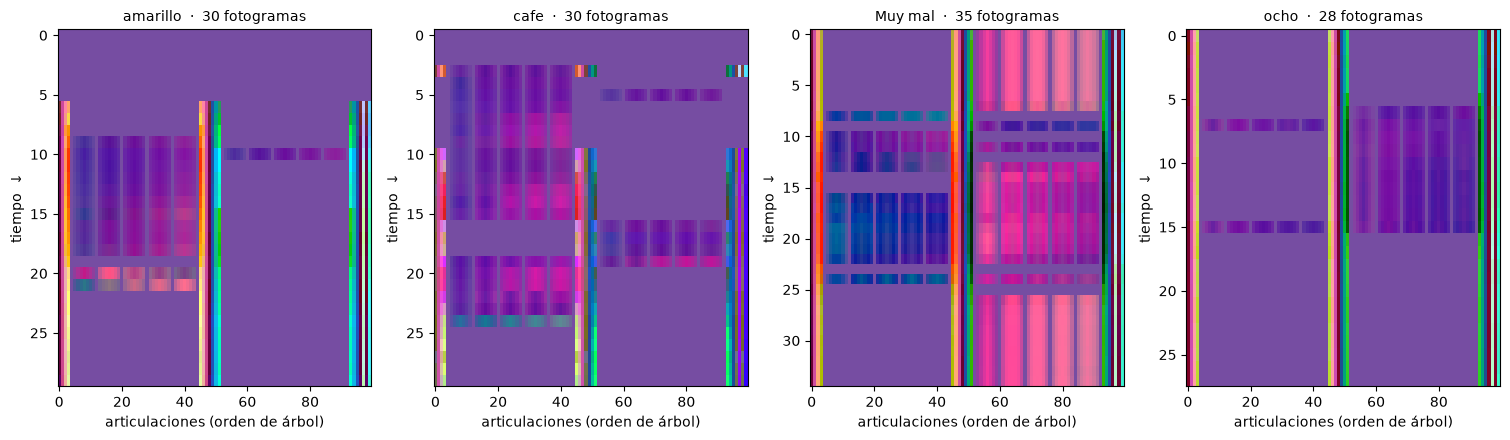

In [12]:
# Así se ven cuatro señas convertidas en imagen.
muestras_tssi = []
for glosa in ("amarillo", "cafe", "Muy mal", "ocho"):
    hallado = next((e for e in train_raw if e["gloss"] == glosa), None)
    if hallado is not None:
        muestras_tssi.append(hallado)
muestras_tssi = muestras_tssi or train_raw[:4]

fig, axes = plt.subplots(1, len(muestras_tssi), figsize=(3.8 * len(muestras_tssi), 4.5))
for ax, ejemplo in zip(np.atleast_1d(axes), muestras_tssi):
    imagen = escalar_a_imagen(a_imagen_tssi(ejemplo["sign"]))
    ax.imshow(imagen.permute(1, 2, 0).numpy(), aspect="auto", interpolation="nearest")
    ax.set_title(f"{ejemplo['gloss']}  ·  {imagen.shape[1]} fotogramas", fontsize=10)
    ax.set_xlabel("articulaciones (orden de árbol)")
    ax.set_ylabel("tiempo  ↓")
plt.tight_layout()
plt.show()

## Entrenamiento

| Decisión | Valor | Por qué |
|---|---|---|
| Red | DenseNet-121 preentrenada en ImageNet | Es lo que propone el artículo |
| Tamaño de entrada | 128×128 | Compromiso entre detalle y costo en CPU |
| Normalización | Media y desviación de ImageNet | Lo que esperan los pesos preentrenados |
| Capa de salida | 1024 → 54 | Reemplaza la de ImageNet (1000 clases) |
| Optimizador | Adam, LR 1e-4 | |
| Lote | 16 | |
| Parada temprana | 6 épocas sin mejorar en validación | En la primera versión el modelo seguía 30 épocas sin ganar nada |
| LR adaptativo | `ReduceLROnPlateau`, LR ÷ 2 | |

Aunque ImageNet sean fotos de objetos, la red ya sabe detectar bordes, texturas y
patrones repetidos, y eso también aplica a una imagen TSSI. Es la ventaja que el
artículo reivindica de convertir el problema a imágenes.

El entrenamiento se detuvo en la **época 21 de 25** y tardó **2 h 11 min**.

In [13]:
import torch.nn.functional as F
from torch.utils.data import Dataset
from torchvision.models import densenet121, DenseNet121_Weights

TAMANO = 128
MEDIA_IMAGENET = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
DESV_IMAGENET  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def precomputar_tssi(datos):
    """Construye las imágenes TSSI una sola vez; son livianas."""
    imagenes = [escalar_a_imagen(a_imagen_tssi(e["sign"])) for e in datos]
    etiquetas = torch.tensor([A_INDICE[e["gloss"]] for e in datos])
    return imagenes, etiquetas


class DatosTSSI(Dataset):
    """Redimensiona y normaliza al vuelo, por lote."""

    def __init__(self, imagenes, etiquetas):
        self.imagenes, self.etiquetas = imagenes, etiquetas

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        img = self.imagenes[i].unsqueeze(0)
        img = F.interpolate(img, size=(TAMANO, TAMANO),
                            mode="bilinear", align_corners=False).squeeze(0)
        return (img - MEDIA_IMAGENET) / DESV_IMAGENET, self.etiquetas[i]


def construir_densenet(n_clases):
    modelo = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
    modelo.classifier = nn.Linear(1024, n_clases)
    return modelo


print("Construyendo imágenes TSSI...")
img_tr, y_tr = precomputar_tssi(train_raw)
img_dv, y_dv = precomputar_tssi(dev_raw)
img_te, y_te = precomputar_tssi(test_raw)

datos_tr, datos_dv, datos_te = DatosTSSI(img_tr, y_tr), DatosTSSI(img_dv, y_dv), DatosTSSI(img_te, y_te)
memoria = sum(i.numel() for i in img_tr + img_dv + img_te) * 4 / 1e6
print(f"  train {len(img_tr)} | dev {len(img_dv)} | test {len(img_te)}")
print(f"  memoria ocupada: {memoria:.0f} MB")
print(f"  forma que entra a la red: {tuple(datos_tr[0][0].shape)}")

Construyendo imágenes TSSI...
  train 1733 | dev 579 | test 568
  memoria ocupada: 180 MB
  forma que entra a la red: (3, 128, 128)


In [14]:
DIR_TSSI = MODELOS / "sl_tssi_v2"
RUTA_TSSI = DIR_TSSI / "best.pt"


def entrenar_tssi(epocas=25, lr=1e-4, paciencia=6, semilla=42):
    """Entrena la DenseNet y guarda pesos e historial por época."""
    torch.manual_seed(semilla)
    modelo = construir_densenet(len(CLASES))
    optim = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()
    planificador = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode="max", factor=0.5, patience=2)

    cargador_tr = DataLoader(datos_tr, batch_size=16, shuffle=True)
    cargador_dv = DataLoader(datos_dv, batch_size=32)

    def evaluar(cargador):
        modelo.eval()
        perdida = aciertos = total = 0
        with torch.no_grad():
            for xb, yb in cargador:
                salida = modelo(xb)
                perdida += criterio(salida, yb).item() * yb.numel()
                aciertos += (salida.argmax(1) == yb).sum().item()
                total += yb.numel()
        return perdida / total, aciertos / total

    historial, mejor_dev, mejores_pesos, epoca_mejor = [], 0.0, None, 0
    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        modelo.train()
        perdida_tr = aciertos_tr = vistos = 0
        for xb, yb in cargador_tr:
            optim.zero_grad()
            salida = modelo(xb)
            perdida = criterio(salida, yb)
            perdida.backward()
            optim.step()
            # Métricas de entrenamiento acumuladas en la misma pasada, sin costo extra.
            perdida_tr += perdida.item() * yb.numel()
            aciertos_tr += (salida.argmax(1) == yb).sum().item()
            vistos += yb.numel()

        perdida_dev, acc_dev = evaluar(cargador_dv)
        planificador.step(acc_dev)

        marca = ""
        if acc_dev > mejor_dev:
            mejor_dev, epoca_mejor = acc_dev, epoca
            mejores_pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
            marca = "  *"
        historial.append({"epoca": epoca,
                          "perdida_train": perdida_tr / vistos,
                          "acc_train": aciertos_tr / vistos,
                          "perdida_dev": perdida_dev,
                          "acc_dev": acc_dev,
                          "lr": optim.param_groups[0]["lr"],
                          "minutos": (time.perf_counter() - inicio) / 60})
        print(f"época {epoca:2d}/{epocas}  pérdida {perdida_tr / vistos:.3f}  "
              f"train {aciertos_tr / vistos:.1%}  dev {acc_dev:.1%}  "
              f"({historial[-1]['minutos']:.1f} min){marca}")

        if epoca - epoca_mejor >= paciencia:
            print(f"\nParada temprana: {paciencia} épocas sin mejorar.")
            break

    modelo.load_state_dict(mejores_pesos)
    DIR_TSSI.mkdir(parents=True, exist_ok=True)
    torch.save({"model_state": mejores_pesos, "clases": CLASES, "tamano": TAMANO,
                "orden_tssi": ORDEN_TSSI, "acc_dev": mejor_dev,
                "epoca_mejor": epoca_mejor, "historial": historial},
               RUTA_TSSI)
    (DIR_TSSI / "historial.json").write_text(json.dumps(historial, indent=2), encoding="utf-8")
    print(f"\nMejor dev: {mejor_dev:.1%} (época {epoca_mejor}) · guardado en {RUTA_TSSI.name}")
    return modelo, historial


if RUTA_TSSI.is_file():
    guardado = torch.load(RUTA_TSSI, map_location="cpu")
    pesos = guardado.get("model_state", guardado)
    assert guardado.get("clases", CLASES) == CLASES, "Las clases del modelo guardado no coinciden"
    modelo_tssi = construir_densenet(len(CLASES))
    modelo_tssi.load_state_dict(pesos)
    modelo_tssi.eval()
    historial_tssi = guardado.get("historial")
    print(f"Modelo ya entrenado, no se reentrena: {RUTA_TSSI.relative_to(ROOT).as_posix()}")
    if guardado.get("acc_dev") is not None:
        print(f"Mejor validación: {guardado['acc_dev']:.1%} (época {guardado.get('epoca_mejor', '?')})")
else:
    modelo_tssi, historial_tssi = entrenar_tssi()

# Predicciones sobre el conjunto de prueba.
predichas = []
with torch.no_grad():
    for xb, _ in DataLoader(datos_te, batch_size=32):
        predichas.append(modelo_tssi(xb).argmax(1))
pred_tssi = torch.cat(predichas)
acc_tssi = (pred_tssi == y_te).float().mean().item()
N_PARAMS_TSSI = sum(p.numel() for p in modelo_tssi.parameters())

print(f"\nExactitud en prueba: {acc_tssi:.1%}  "
      f"({len(y_te)} videos de {len({e['signer'] for e in test_raw})} personas nunca vistas)")
print(f"Parámetros: {N_PARAMS_TSSI:,}")

Modelo ya entrenado, no se reentrena: modelos/sl_tssi_v2/best.pt
Mejor validación: 92.2% (época 15)

Exactitud en prueba: 84.7%  (568 videos de 7 personas nunca vistas)
Parámetros: 7,009,206


## Curva de aprendizaje

Registramos pérdida y exactitud en entrenamiento y en validación por cada época, así que
se puede comparar lo que el modelo memoriza con lo que de verdad generaliza.

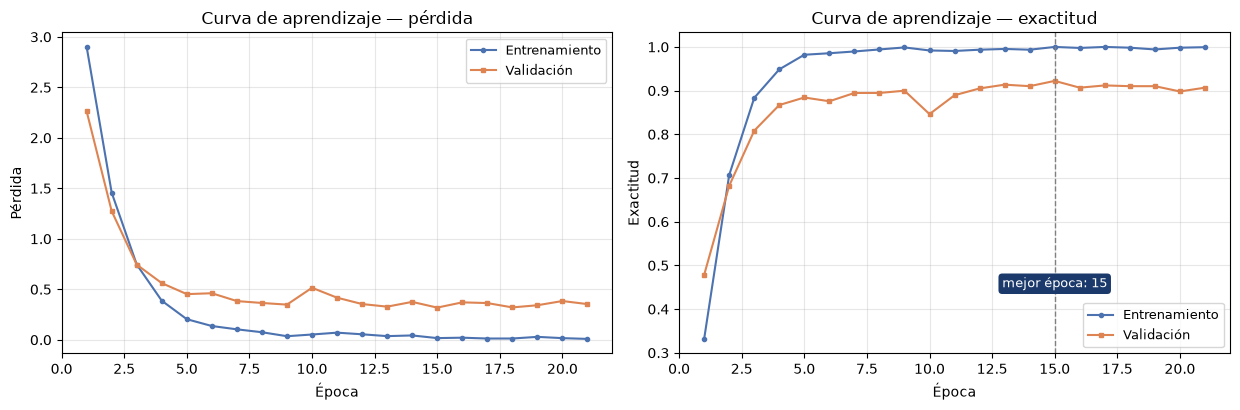

Entrenamiento llega a 100.0% y validación se queda en 92.2%.
La parada temprana acortó el entrenamiento, pero el sobreajuste sigue ahí:
el modelo memoriza los 1,733 videos de entrenamiento antes de generalizar.


In [15]:
RUTA_HIST = DIR_TSSI / "historial.json"
if not historial_tssi and RUTA_HIST.is_file():
    historial_tssi = json.loads(RUTA_HIST.read_text(encoding="utf-8"))

if isinstance(historial_tssi, dict):          # por si quedó guardado como columnas
    historial_tssi = [dict(zip(historial_tssi, v)) for v in zip(*historial_tssi.values())]
if historial_tssi and not isinstance(historial_tssi[0], dict):
    historial_tssi = [dict(zip(("epoca", "perdida_train", "acc_dev"), f)) for f in historial_tssi]


def serie(historial, *nombres):
    """Saca una columna del historial probando los nombres posibles."""
    for n in nombres:
        if all(isinstance(f, dict) and n in f for f in historial):
            return [f[n] for f in historial]
    return None


if not historial_tssi:
    print("No hay historial guardado: la curva solo se puede dibujar entrenando.")
else:
    h = historial_tssi
    epocas = serie(h, "epoca", "epoch") or list(range(1, len(h) + 1))
    p_tr = serie(h, "perdida_train", "perdida", "loss_train", "train_loss")
    p_dv = serie(h, "perdida_dev", "loss_dev", "val_loss", "dev_loss")
    a_tr = serie(h, "acc_train", "train_acc", "exactitud_train")
    a_dv = serie(h, "acc_dev", "dev", "dev_acc", "val_acc")
    mejor = int(np.argmax(a_dv)) if a_dv else None

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
    for ax, (tr, dv), titulo, etiqueta_y in (
            (ax1, (p_tr, p_dv), "Curva de aprendizaje — pérdida", "Pérdida"),
            (ax2, (a_tr, a_dv), "Curva de aprendizaje — exactitud", "Exactitud")):
        if tr:
            ax.plot(epocas, tr, color=AZUL, marker="o", ms=3, label="Entrenamiento")
        if dv:
            ax.plot(epocas, dv, color=NARANJA, marker="s", ms=3, label="Validación")
        ax.set_xlabel("Época")
        ax.set_ylabel(etiqueta_y)
        ax.set_title(titulo)
        ax.grid(alpha=0.3)
        if tr or dv:
            ax.legend(fontsize=9)
    if mejor is not None:
        ax2.axvline(epocas[mejor], color="gray", ls="--", lw=1)
        ax2.annotate(f"mejor época: {epocas[mejor]}", (epocas[mejor], 0.45),
                     ha="center", fontsize=9,
                     bbox=dict(boxstyle="round,pad=0.3", fc="#1b3a6b", ec="none"),
                     color="white")
    plt.tight_layout()
    plt.show()

    if a_tr and a_dv:
        print(f"Entrenamiento llega a {max(a_tr):.1%} y validación se queda en {max(a_dv):.1%}.")
        print("La parada temprana acortó el entrenamiento, pero el sobreajuste sigue ahí:")
        print(f"el modelo memoriza los {len(train_raw):,} videos de entrenamiento antes de generalizar.")

---
# 5. Aumento de datos

El modelo SL-TSSI llega a **100 % en entrenamiento** pero se queda en **92,2 % en
validación** y **84,7 % en prueba**: memoriza los 1.733 videos de entrenamiento. El aumento
de datos ataca justo eso. En cada época el modelo recibe una versión ligeramente distinta
de cada video, así que ya no hay un conjunto fijo que aprenderse de memoria.

**Qué se transforma.** La matriz cruda de MediaPipe, `(fotogramas, 225)`, antes de
normalizar y de construir la imagen TSSI. Los videos no se tocan: volver a pasar MediaPipe
por cada variante costaría horas, y el modelo nunca ve píxeles.

**Cuándo.** Al vuelo, dentro del `Dataset`: cada vez que el entrenamiento pide un video se
genera una variante nueva al azar. No se guarda nada en disco, y solo se aumenta train;
validación y prueba quedan intactos.

**Qué transformaciones sirven.** El propio pipeline anula algunas. Lo medimos en 200 videos
de train, comparando lo que llega al modelo con y sin cada transformación:

| Transformación | Cambio medido | |
|---|---|---|
| Trasladar a la persona | 0 % | La normalización la centra en los hombros y cada mano en su muñeca |
| Escalar (acercarse a la cámara) | 0 % | La normalización divide por el ancho de hombros y el tamaño de la mano |
| Velocidad uniforme ×0,8 o ×1,2 | 2–3 % | Toda imagen termina con 128 filas de tiempo |
| Rotar 10° | 11,6 % | Sobrevive |
| Estirar x e y en distinta proporción | 12,7 % | Sobrevive |
| Una parte de la seña más rápida que otra | 6,5 % | Sobrevive |
| Recortar el 10 % de los fotogramas | 7,7 % | Sobrevive |

Las transformaciones espaciales se midieron sobre las coordenadas normalizadas, y las de
tiempo sobre la imagen 128×128 que entra a la red. Trasladar y escalar se descartan. De las
de tiempo solo se usan las que cambian el ritmo de forma desigual.

Las seis que se usan:

| Transformación | Qué simula | Valores | Probabilidad |
|---|---|---|---|
| Recorte temporal | Grabación que empieza o termina antes | hasta 10 % de los fotogramas | 0,5 |
| Deformación temporal | Una parte de la seña más rápida que la otra | factor 0,8 a 1,2 | 0,5 |
| Rotación | Cámara o persona algo inclinada | ±12° | 0,5 |
| Estiramiento | Otra proporción de cuerpo o de cámara | x e y entre 0,9 y 1,1, por separado | 0,5 |
| Ruido | Temblor de MediaPipe | σ = 0,002 en x, y | 0,5 |
| Quitar una mano | MediaPipe pierde la mano unos fotogramas | bloque del 10 % del video | 0,3 |

Un punto que MediaPipe no detectó (cero) **sigue siendo cero** después de cualquier
transformación, y el azar usa una semilla fija. No se usa el espejo horizontal: cambia la
mano dominante, y en lengua de señas eso puede cambiar la seña.

In [16]:
import math

AUMENTO = {
    "p_recortar": 0.5, "recorte_max": 0.10,        # fracción quitada entre inicio y final
    "p_deformar": 0.5, "deformar": (0.8, 1.2),     # ritmo de una parte frente a la otra
    "p_rotar": 0.5, "grados": 12.0,                # giro en el plano x, y
    "p_estirar": 0.5, "estirar": (0.9, 1.1),       # factor distinto en x y en y
    "p_ruido": 0.5, "sigma": 0.002,                # ruido gaussiano en x, y
    "p_quitar_mano": 0.3, "quitar_frac": 0.10,     # bloque de fotogramas sin una mano
}


def _presentes(p):
    """(T, 75): True donde MediaPipe detectó el punto. Los ausentes son ceros."""
    return p.abs().sum(-1) > 0


def _transformar_xy(s, funcion):
    """Aplica `funcion` a las x, y de los puntos presentes, alrededor del centro de los hombros."""
    p = s.reshape(s.shape[0], 75, 3).clone()
    presentes = _presentes(p)
    con_hombros = presentes[:, HOMBRO_IZQ] & presentes[:, HOMBRO_DER]
    if con_hombros.any():
        c = ((p[con_hombros, HOMBRO_IZQ, :2] + p[con_hombros, HOMBRO_DER, :2]) / 2).mean(0)
    else:
        c = torch.tensor([0.5, 0.5])
    nuevo = funcion(p[..., :2] - c) + c
    p[..., :2] = torch.where(presentes[..., None], nuevo, p[..., :2])
    return p.reshape(s.shape)


def rotar(s, grados):
    a = math.radians(grados)
    R = torch.tensor([[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]])
    return _transformar_xy(s, lambda xy: xy @ R.T)


def estirar(s, fx, fy):
    return _transformar_xy(s, lambda xy: xy * torch.tensor([fx, fy]))


def ruido(s, sigma, generador=None):
    p = s.reshape(s.shape[0], 75, 3).clone()
    r = torch.randn(p[..., :2].shape, generator=generador) * sigma
    p[..., :2] = torch.where(_presentes(p)[..., None], p[..., :2] + r, p[..., :2])
    return p.reshape(s.shape)


def _interpolar(s, posiciones):
    """Muestrea la secuencia en posiciones fraccionarias.

    Interpola solo si el punto está presente en los dos fotogramas vecinos; si no, toma el
    más cercano. Así una mano ausente no se convierte en una mano «a medias».
    """
    T = s.shape[0]
    p = s.reshape(T, 75, 3)
    presentes = _presentes(p)
    i0 = posiciones.floor().long().clamp(0, T - 1)
    i1 = (i0 + 1).clamp(max=T - 1)
    w = (posiciones - i0.float()).clamp(0, 1).view(-1, 1, 1)
    lineal = (1 - w) * p[i0] + w * p[i1]
    cercano = torch.where(w < 0.5, p[i0], p[i1])
    ambos = (presentes[i0] & presentes[i1])[..., None]
    return torch.where(ambos, lineal, cercano).reshape(len(posiciones), -1)


def deformar_tiempo(s, factor, corte=0.5):
    """La parte antes de `corte` dura `factor` veces lo que duraba; la de después se ajusta.

    El número de fotogramas no cambia, así que la duración total tampoco.
    """
    T = s.shape[0]
    if T < 4:
        return s.clone()
    n = T - 1
    a = corte * n                                        # quiebre en la entrada
    a_salida = n * a * factor / (a * factor + (n - a))   # dónde cae en la salida
    u = torch.arange(T, dtype=torch.float32)
    t = torch.where(u <= a_salida, u * a / a_salida,
                    a + (u - a_salida) * (n - a) / (n - a_salida))
    return _interpolar(s, t)


def quitar_mano(s, mano, inicio, largo):
    """Pone en cero una mano en un bloque de fotogramas, como cuando MediaPipe la pierde."""
    s = s.clone()
    columnas = slice(99, 162) if mano == "izquierda" else slice(162, 225)
    s[inicio: inicio + largo, columnas] = 0
    return s


def aumentar(secuencia, generador=None, cfg=AUMENTO):
    """Aplica al azar las transformaciones de `cfg` a una matriz cruda (T, 225)."""
    g = generador
    uniforme = lambda a, b: a + (b - a) * torch.rand(1, generator=g).item()
    moneda = lambda p: p > 0 and torch.rand(1, generator=g).item() < p
    s = secuencia.float().clone()

    if moneda(cfg["p_recortar"]):
        T = s.shape[0]
        total = min(int(uniforme(0, cfg["recorte_max"]) * T), max(0, T - 8))
        inicio = int(torch.randint(0, total + 1, (1,), generator=g).item())
        s = s[inicio: T - (total - inicio)].clone()
    if moneda(cfg["p_deformar"]):
        s = deformar_tiempo(s, uniforme(*cfg["deformar"]), uniforme(0.3, 0.7))
    if moneda(cfg["p_rotar"]):
        s = rotar(s, uniforme(-cfg["grados"], cfg["grados"]))
    if moneda(cfg["p_estirar"]):
        s = estirar(s, uniforme(*cfg["estirar"]), uniforme(*cfg["estirar"]))
    if moneda(cfg["p_ruido"]):
        s = ruido(s, cfg["sigma"], g)
    if moneda(cfg["p_quitar_mano"]):
        T = s.shape[0]
        largo = max(1, round(cfg["quitar_frac"] * T))
        inicio = int(torch.randint(0, T - largo + 1, (1,), generator=g).item())
        s = quitar_mano(s, "izquierda" if moneda(0.5) else "derecha", inicio, largo)
    return s


class DatosTSSIAumentados(Dataset):
    """Guarda la matriz cruda y arma una imagen TSSI distinta cada vez que se pide."""

    def __init__(self, datos, generador):
        self.secuencias = [e["sign"].float() for e in datos]
        self.etiquetas = torch.tensor([A_INDICE[e["gloss"]] for e in datos])
        self.generador = generador

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        s = aumentar(self.secuencias[i], self.generador)
        img = escalar_a_imagen(a_imagen_tssi(s)).unsqueeze(0)
        img = F.interpolate(img, size=(TAMANO, TAMANO),
                            mode="bilinear", align_corners=False).squeeze(0)
        return (img - MEDIA_IMAGENET) / DESV_IMAGENET, self.etiquetas[i]


# Comprobaciones sobre 300 videos de train.
g = torch.Generator().manual_seed(0)
for e in train_raw[:300]:
    s = e["sign"].float()
    ausentes = ~_presentes(s.reshape(-1, 75, 3))
    girada = ruido(estirar(rotar(s, 10), 1.1, 0.9), 0.002, g)
    assert torch.equal(~_presentes(girada.reshape(-1, 75, 3)), ausentes)
    a = aumentar(s, g)
    assert a.shape[1] == 225 and 8 <= a.shape[0] <= s.shape[0] and torch.isfinite(a).all()
print("Comprobado en 300 videos: los puntos ausentes siguen en cero y todas las")
print("versiones aumentadas tienen 225 columnas y al menos 8 fotogramas.")

Comprobado en 300 videos: los puntos ausentes siguen en cero y todas las
versiones aumentadas tienen 225 columnas y al menos 8 fotogramas.


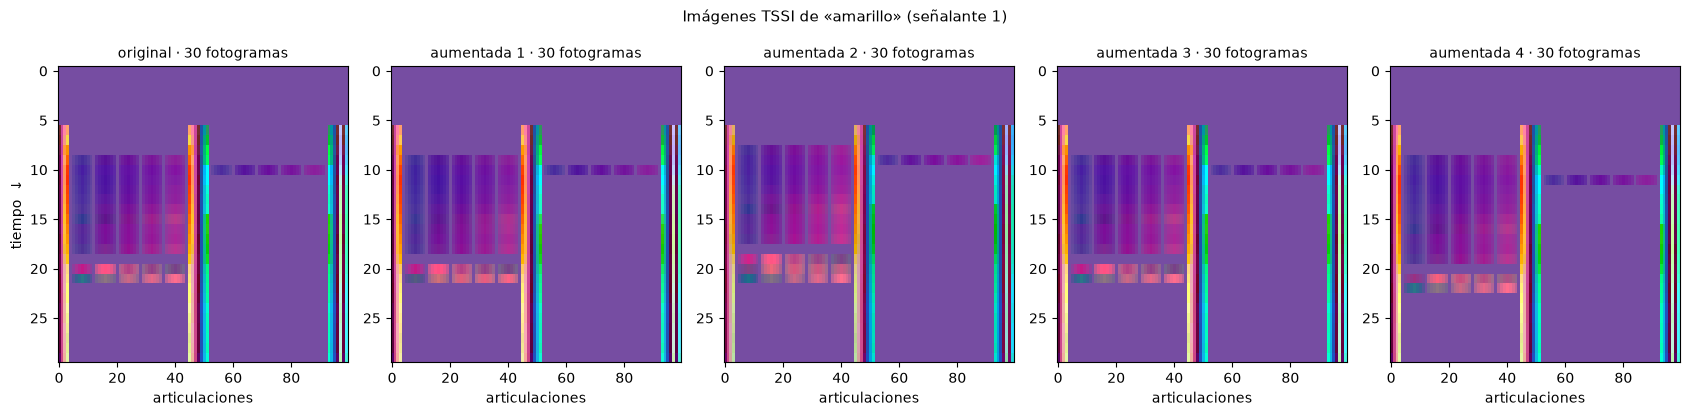

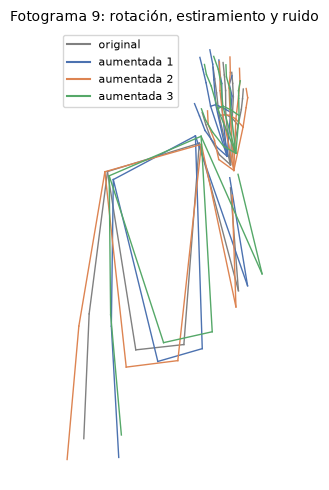

In [17]:
# La misma seña, original y en cuatro versiones aumentadas.
ejemplo = next(e for e in train_raw if e["gloss"] == "amarillo")
g = torch.Generator().manual_seed(7)
versiones = [("original", ejemplo["sign"].float())] + [
    (f"aumentada {i}", aumentar(ejemplo["sign"], g)) for i in range(1, 5)]

fig, axes = plt.subplots(1, 5, figsize=(17, 4.2))
for ax, (titulo, s) in zip(axes, versiones):
    imagen = escalar_a_imagen(a_imagen_tssi(s))
    ax.imshow(imagen.permute(1, 2, 0).numpy(), aspect="auto", interpolation="nearest")
    ax.set_title(f"{titulo} · {s.shape[0]} fotogramas", fontsize=10)
    ax.set_xlabel("articulaciones")
axes[0].set_ylabel("tiempo  ↓")
fig.suptitle(f"Imágenes TSSI de «{ejemplo['gloss']}» (señalante {ejemplo['signer']})", fontsize=11)
plt.tight_layout()
plt.show()

# Un fotograma del esqueleto con las transformaciones espaciales superpuestas.
espacial = {k: (0.0 if k.startswith("p_") else v) for k, v in AUMENTO.items()}
espacial.update(p_rotar=1.0, p_estirar=1.0, p_ruido=1.0)
s = ejemplo["sign"].float()
t = max(range(s.shape[0]), key=lambda i: int((s[i, 99:].abs().sum() > 0).item()))


def dibujar_lineas(ax, fila, color, etiqueta):
    for puntos, conexiones in ((fila[0:99].reshape(33, 3), CONEX_POSE),
                               (fila[99:162].reshape(21, 3), CONEX_MANO),
                               (fila[162:225].reshape(21, 3), CONEX_MANO)):
        if puntos.abs().sum() == 0:
            continue
        for a, b in conexiones:
            ax.plot([puntos[a, 0], puntos[b, 0]], [puntos[a, 1], puntos[b, 1]], color=color, lw=1)
    ax.plot([], [], color=color, label=etiqueta)


fig, ax = plt.subplots(figsize=(5, 5))
dibujar_lineas(ax, s[t], "gray", "original")
for i, color in enumerate((AZUL, NARANJA, VERDE)):
    dibujar_lineas(ax, aumentar(s, g, espacial)[t], color, f"aumentada {i + 1}")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.axis("off")
ax.legend(fontsize=8)
ax.set_title(f"Fotograma {t}: rotación, estiramiento y ruido", fontsize=10)
plt.tight_layout()
plt.show()

## Entrenamiento con aumento

Todo es igual al modelo anterior salvo el aumento y el número máximo de épocas, así que la
diferencia entre los dos se puede atribuir al aumento.

| | Sin aumento | Con aumento |
|---|---|---|
| Red, entrada, optimizador, lote, LR adaptativo | ver tabla de la sección 4 | igual |
| Parada temprana | 6 épocas sin mejorar en validación | igual |
| Semilla | 42 | igual |
| Épocas máximas | 25 | **40**: con aumento el modelo tarda más en converger |
| Datos de train | los mismos en cada época | **una versión aumentada distinta en cada época** |

Con aumento, la exactitud que se mide mientras se entrena es sobre datos aumentados, que
son más difíciles que los originales. Para saber de verdad cuánto memoriza el modelo, al
final de cada época se evalúan también **300 videos fijos de train sin aumentar**.

El entrenamiento se detuvo en la **época 22 de 40** (la mejor fue la 16) y tardó
**2 h 47 min**, unos 7,5 minutos por época.

In [18]:
DIR_AUG = MODELOS / "sl_tssi_aug"
RUTA_AUG = DIR_AUG / "best.pt"


def entrenar_tssi_aumentado(epocas=40, lr=1e-4, paciencia=6, semilla=42, n_control=300):
    """Como entrenar_tssi, pero cada época ve una versión aumentada distinta de train."""
    g_aumento = torch.Generator().manual_seed(semilla)
    g_orden = torch.Generator().manual_seed(semilla + 1)
    datos_aum = DatosTSSIAumentados(train_raw, g_aumento)
    # Videos fijos de train sin aumentar: miden cuánto memoriza el modelo.
    control = sorted(torch.randperm(len(train_raw), generator=torch.Generator().manual_seed(semilla))
                     [:n_control].tolist())
    datos_control = DatosTSSI([img_tr[i] for i in control], y_tr[control])

    torch.manual_seed(semilla)
    modelo = construir_densenet(len(CLASES))
    optim = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()
    planificador = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode="max", factor=0.5, patience=2)

    cargador_tr = DataLoader(datos_aum, batch_size=16, shuffle=True, generator=g_orden)

    def evaluar(datos):
        modelo.eval()
        perdida = aciertos = 0
        with torch.no_grad():
            for xb, yb in DataLoader(datos, batch_size=32):
                salida = modelo(xb)
                perdida += criterio(salida, yb).item() * yb.numel()
                aciertos += (salida.argmax(1) == yb).sum().item()
        return perdida / len(datos), aciertos / len(datos)

    DIR_AUG.mkdir(parents=True, exist_ok=True)
    historial, mejor_dev, mejores_pesos, epoca_mejor = [], -1.0, None, 0
    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        modelo.train()
        perdida_tr = aciertos_tr = vistos = 0
        for xb, yb in cargador_tr:
            optim.zero_grad()
            salida = modelo(xb)
            perdida = criterio(salida, yb)
            perdida.backward()
            optim.step()
            perdida_tr += perdida.item() * yb.numel()
            aciertos_tr += (salida.argmax(1) == yb).sum().item()
            vistos += yb.numel()

        perdida_dev, acc_dev = evaluar(datos_dv)
        perdida_control, acc_control = evaluar(datos_control)
        planificador.step(acc_dev)

        marca = ""
        if acc_dev > mejor_dev:
            mejor_dev, epoca_mejor = acc_dev, epoca
            mejores_pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
            marca = "  *"
        historial.append({"epoca": epoca,
                          "loss_train": perdida_tr / vistos,        # sobre datos aumentados
                          "acc_train": aciertos_tr / vistos,        # sobre datos aumentados
                          "loss_train_limpio": perdida_control,     # train sin aumentar
                          "acc_train_limpio": acc_control,          # train sin aumentar
                          "loss_dev": perdida_dev,
                          "acc_dev": acc_dev,
                          "lr": optim.param_groups[0]["lr"],
                          "minutos": (time.perf_counter() - inicio) / 60})
        (DIR_AUG / "historial.json").write_text(json.dumps(historial, indent=2), encoding="utf-8")
        print(f"época {epoca:2d}/{epocas}  pérdida {perdida_tr / vistos:.3f}  "
              f"train aum. {aciertos_tr / vistos:.1%}  train sin aum. {acc_control:.1%}  "
              f"dev {acc_dev:.1%}  ({historial[-1]['minutos']:.1f} min){marca}")

        if epoca - epoca_mejor >= paciencia:
            print(f"\nParada temprana: {paciencia} épocas sin mejorar.")
            break

    modelo.load_state_dict(mejores_pesos)
    modelo.eval()
    torch.save({"model_state": mejores_pesos, "clases": CLASES, "tamano": TAMANO,
                "orden_tssi": ORDEN_TSSI, "semilla": semilla, "p_bajo": P_BAJO, "p_alto": P_ALTO,
                "acc_dev": mejor_dev, "epoca_mejor": epoca_mejor, "historial": historial,
                "aumento": AUMENTO}, RUTA_AUG)
    print(f"\nMejor dev: {mejor_dev:.1%} (época {epoca_mejor}) · guardado en {RUTA_AUG.name}")
    return modelo, historial


if RUTA_AUG.is_file():
    guardado = torch.load(RUTA_AUG, map_location="cpu", weights_only=False)
    assert guardado["clases"] == CLASES, "Las clases del modelo guardado no coinciden"
    assert torch.allclose(guardado["p_bajo"], P_BAJO) and torch.allclose(guardado["p_alto"], P_ALTO), \
        "El escalado de las imágenes no coincide con el del entrenamiento"
    modelo_aug = construir_densenet(len(CLASES))
    modelo_aug.load_state_dict(guardado["model_state"])
    modelo_aug.eval()
    historial_aug = guardado["historial"]
    print(f"Modelo ya entrenado, no se reentrena: {RUTA_AUG.relative_to(ROOT).as_posix()}")
    print(f"Mejor validación: {guardado['acc_dev']:.1%} "
          f"(época {guardado['epoca_mejor']} de {len(historial_aug)} entrenadas)")
else:
    modelo_aug, historial_aug = entrenar_tssi_aumentado()

# Predicciones sobre el conjunto de prueba (sin aumento, como siempre).
predichas = []
with torch.no_grad():
    for xb, _ in DataLoader(datos_te, batch_size=32):
        predichas.append(modelo_aug(xb).argmax(1))
pred_aug = torch.cat(predichas)
acc_aug = (pred_aug == y_te).float().mean().item()

print(f"\nExactitud en prueba: {acc_aug:.1%}   (sin aumento: {acc_tssi:.1%}, "
      f"{acc_aug - acc_tssi:+.1%})")

Modelo ya entrenado, no se reentrena: modelos/sl_tssi_aug/best.pt
Mejor validación: 92.7% (época 16 de 22 entrenadas)

Exactitud en prueba: 87.1%   (sin aumento: 84.7%, +2.5%)


## Curvas de aprendizaje: sin aumento y con aumento

Si el aumento funciona, la distancia entre entrenamiento y validación debería ser menor.
Para el modelo con aumento, la curva de entrenamiento es la de los 300 videos sin aumentar.

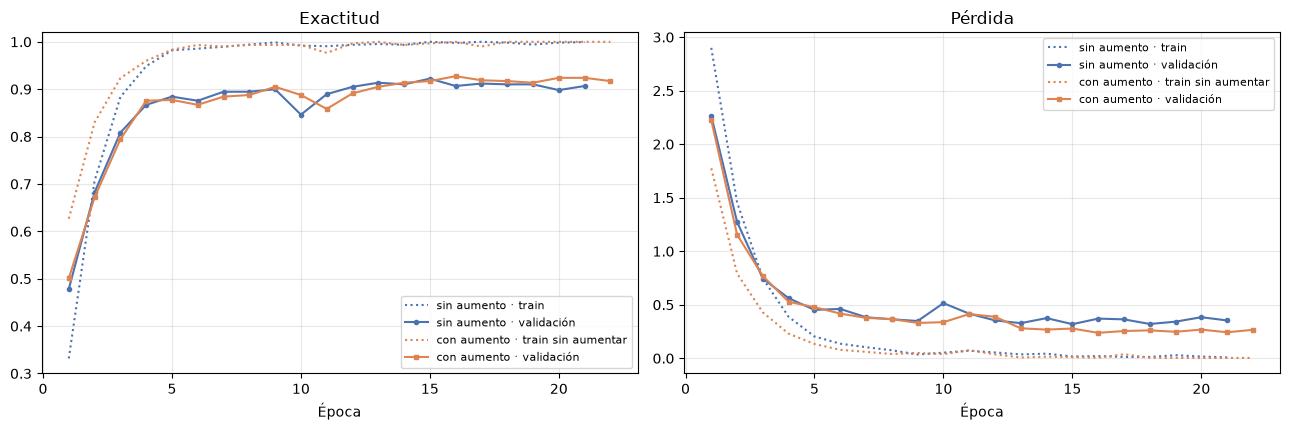

                  train  validación   brecha  mejor época  pérdida dev mín.
----------------------------------------------------------------------------
sin aumento     100.0%      92.2%   +7.8%           15              0.32
con aumento     100.0%      92.7%   +7.3%           16              0.24

Valores en la mejor época de cada modelo, que es la que se guarda.
La pérdida en validación baja bastante, pero train sigue llegando al 100 %:
el aumento ayuda a generalizar, aunque no elimina la memorización.


In [19]:
h_v2, h_aug = historial_tssi, historial_aug
ep_v2 = serie(h_v2, "epoca", "epoch") or list(range(1, len(h_v2) + 1))
ep_aug = serie(h_aug, "epoca")
curvas = {
    "Exactitud": (serie(h_v2, "acc_train"), serie(h_v2, "acc_dev"),
                  serie(h_aug, "acc_train_limpio"), serie(h_aug, "acc_dev")),
    "Pérdida": (serie(h_v2, "perdida_train", "loss_train"), serie(h_v2, "perdida_dev", "loss_dev"),
                serie(h_aug, "loss_train_limpio"), serie(h_aug, "loss_dev")),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (titulo, (tr_v2, dv_v2, tr_aug, dv_aug)) in zip(axes, curvas.items()):
    ax.plot(ep_v2, tr_v2, color=AZUL, ls=":", label="sin aumento · train")
    ax.plot(ep_v2, dv_v2, color=AZUL, marker="o", ms=3, label="sin aumento · validación")
    ax.plot(ep_aug, tr_aug, color=NARANJA, ls=":", label="con aumento · train sin aumentar")
    ax.plot(ep_aug, dv_aug, color=NARANJA, marker="s", ms=3, label="con aumento · validación")
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylim(0.3, 1.02)
plt.tight_layout()
plt.show()

print(f"{'':<14} {'train':>8} {'validación':>11} {'brecha':>8} {'mejor época':>12} "
      f"{'pérdida dev mín.':>17}")
print("-" * 76)
for nombre, ep, (tr, dv) in (("sin aumento", ep_v2, curvas["Exactitud"][:2]),
                             ("con aumento", ep_aug, curvas["Exactitud"][2:])):
    perdida_dev = curvas["Pérdida"][1] if nombre == "sin aumento" else curvas["Pérdida"][3]
    i = int(np.argmax(dv))
    print(f"{nombre:<14} {tr[i]:>7.1%} {dv[i]:>10.1%} {tr[i] - dv[i]:>+7.1%} {ep[i]:>12} "
          f"{min(perdida_dev):>17.2f}")

print("\nValores en la mejor época de cada modelo, que es la que se guarda.")
print("La pérdida en validación baja bastante, pero train sigue llegando al 100 %:")
print("el aumento ayuda a generalizar, aunque no elimina la memorización.")

---
# 6. Resultados

Los cuatro modelos se entrenaron con los mismos datos y la misma división, y se evalúan
sobre el mismo conjunto de prueba, que nunca se usó para elegir ningún modelo.
«SL-TSSI-DenseNet» es el modelo de la sección 4 y «SL-TSSI + aumento», el de la 5.

La exactitud global promedia todos los videos por igual, y con un conjunto desbalanceado
(75 videos de entrenamiento por color frente a 14 por algunas señas de cortesía) eso
favorece a las clases grandes. El **F1 macro** corrige ese sesgo: calcula el F1 de cada
seña por separado y promedia, dándoles el mismo peso.

In [20]:
def metricas_por_clase(reales, predichas, clases):
    """Precisión, recall y F1 de cada clase."""
    tp, fp, fn = Counter(), Counter(), Counter()
    for r, p in zip(reales, predichas):
        if r == p:
            tp[r] += 1
        else:
            fp[p] += 1
            fn[r] += 1

    filas = {}
    for c in clases:
        prec = tp[c] / (tp[c] + fp[c]) if (tp[c] + fp[c]) else 0.0
        rec = tp[c] / (tp[c] + fn[c]) if (tp[c] + fn[c]) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        filas[c] = {"precision": prec, "recall": rec, "f1": f1, "soporte": tp[c] + fn[c]}
    return filas


def evaluar_modelo(reales, predichas):
    filas = metricas_por_clase(reales, predichas, CLASES)
    presentes = [c for c in CLASES if filas[c]["soporte"] > 0]
    n = len(presentes)

    por_categoria = defaultdict(lambda: [0, 0])
    for r, h in zip(reales, predichas):
        por_categoria[grupo.get(r, "?")][0] += int(r == h)
        por_categoria[grupo.get(r, "?")][1] += 1

    resultado = {
        "exactitud": sum(r == h for r, h in zip(reales, predichas)) / len(reales),
        "recall_macro": sum(filas[c]["recall"] for c in presentes) / n,
        "precision_macro": sum(filas[c]["precision"] for c in presentes) / n,
        "f1_macro": sum(filas[c]["f1"] for c in presentes) / n,
        "filas": filas,
    }
    for cat in ("Colores", "Cortesía", "Números"):
        resultado[cat] = por_categoria[cat][0] / por_categoria[cat][1]
    return resultado


reales_str = [e["gloss"] for e in test_raw]
pred_tssi_str = [CLASES[p] for p in pred_tssi.tolist()]
pred_aug_str = [CLASES[p] for p in pred_aug.tolist()]

MODELOS_EVAL = {
    "Transformer original":    (original["ref"], original["hyp"]),
    "Transformer normalizado": (normalizado["ref"], normalizado["hyp"]),
    "SL-TSSI-DenseNet":        (reales_str, pred_tssi_str),
    "SL-TSSI + aumento":       (reales_str, pred_aug_str),
}
PARAMETROS = {
    "Transformer original":    N_PARAMS_SLT,
    "Transformer normalizado": N_PARAMS_SLT,
    "SL-TSSI-DenseNet":        N_PARAMS_TSSI,
    "SL-TSSI + aumento":       N_PARAMS_TSSI,
}
PREENTRENADO = {
    "Transformer original": "No",
    "Transformer normalizado": "No", "SL-TSSI-DenseNet": "Sí (ImageNet)",
    "SL-TSSI + aumento": "Sí (ImageNet)",
}

resultados = {n: evaluar_modelo(ref, hyp) for n, (ref, hyp) in MODELOS_EVAL.items()}

enc = (f"{'MODELO':<25} {'params':>9} {'pre':>14} {'exact.':>8} {'rec.M':>7} "
       f"{'prec.M':>7} {'F1 M':>7} {'Col.':>7} {'Cort.':>7} {'Núm.':>7}")
print(enc)
print("-" * len(enc))
for nombre, r in resultados.items():
    print(f"{nombre:<25} {PARAMETROS[nombre] / 1e6:>7.2f} M {PREENTRENADO[nombre]:>14} "
          f"{r['exactitud']:>7.1%} {r['recall_macro']:>6.1%} {r['precision_macro']:>6.1%} "
          f"{r['f1_macro']:>6.1%} {r['Colores']:>6.1%} {r['Cortesía']:>6.1%} {r['Números']:>6.1%}")

print("\nexact. = exactitud global   ·   rec.M / prec.M / F1 M = promedios macro")
print("El F1 macro de SL-TSSI está cerca de su exactitud, así que no gana solo")
print("por acertar las señas que tienen más videos.")

MODELO                       params            pre   exact.   rec.M  prec.M    F1 M    Col.   Cort.    Núm.
-----------------------------------------------------------------------------------------------------------
Transformer original        22.29 M             No   51.2%  53.2%  56.5%  51.4%  87.5%  56.6%  11.9%
Transformer normalizado     22.29 M             No   65.1%  66.2%  69.5%  65.1%  90.0%  70.7%  34.4%
SL-TSSI-DenseNet             7.01 M  Sí (ImageNet)   84.7%  83.8%  82.3%  82.0%  98.3%  80.5%  82.1%
SL-TSSI + aumento            7.01 M  Sí (ImageNet)   87.1%  85.8%  85.7%  85.2%  96.7%  82.5%  88.7%

exact. = exactitud global   ·   rec.M / prec.M / F1 M = promedios macro
El F1 macro de SL-TSSI está cerca de su exactitud, así que no gana solo
por acertar las señas que tienen más videos.


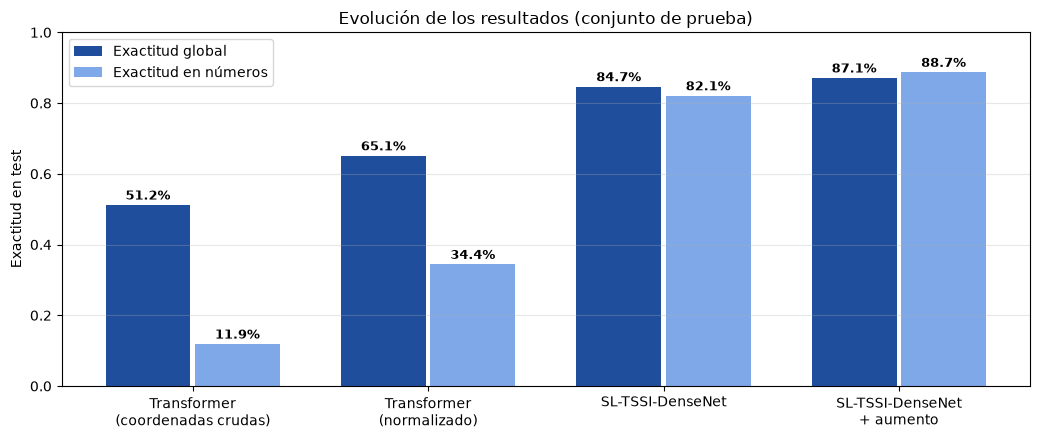

Normalizar las coordenadas: +13.9%
Pasar a SL-TSSI-DenseNet:   +19.5%
Aumento de datos:           +2.5%


In [21]:
# Cómo evolucionaron los resultados en el conjunto de prueba.
ETAPAS = [("Transformer\n(coordenadas crudas)", "Transformer original"),
          ("Transformer\n(normalizado)", "Transformer normalizado"),
          ("SL-TSSI-DenseNet", "SL-TSSI-DenseNet"),
          ("SL-TSSI-DenseNet\n+ aumento", "SL-TSSI + aumento")]
glob = [resultados[k]["exactitud"] for _, k in ETAPAS]
nums = [resultados[k]["Números"] for _, k in ETAPAS]

x = np.arange(len(ETAPAS))
fig, ax = plt.subplots(figsize=(10.5, 4.5))
b1 = ax.bar(x - 0.19, glob, 0.36, label="Exactitud global", color="#1f4e9c")
b2 = ax.bar(x + 0.19, nums, 0.36, label="Exactitud en números", color="#7fa8e8")
for barras in (b1, b2):
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.015,
                f"{barra.get_height():.1%}", ha="center", fontweight="bold", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels([n for n, _ in ETAPAS])
ax.set_ylim(0, 1.0)
ax.set_ylabel("Exactitud en test")
ax.set_title("Evolución de los resultados (conjunto de prueba)")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Normalizar las coordenadas: {glob[1] - glob[0]:+.1%}")
print(f"Pasar a SL-TSSI-DenseNet:   {glob[2] - glob[1]:+.1%}")
print(f"Aumento de datos:           {glob[3] - glob[2]:+.1%}")

In [22]:
# ¿La mejora del aumento es real o puede ser azar? Prueba exacta de McNemar.
# Compara los dos modelos video por video; solo cuentan los videos que uno acierta y el otro no.
solo_v2 = sum(a == r != b for r, a, b in zip(reales_str, pred_tssi_str, pred_aug_str))
solo_aug = sum(b == r != a for r, a, b in zip(reales_str, pred_tssi_str, pred_aug_str))
n, k = solo_v2 + solo_aug, min(solo_v2, solo_aug)
p_valor = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

print("PRUEBA DE McNEMAR: SL-TSSI sin aumento frente a con aumento")
print(f"  videos que solo acierta sin aumento:  {solo_v2}")
print(f"  videos que solo acierta con aumento:  {solo_aug}")
print(f"  valor p: {p_valor:.3f}")
if p_valor < 0.05:
    print("\nLa diferencia es estadísticamente significativa (p < 0,05).")
else:
    print("\nNo llega al umbral de 0,05: con una sola corrida no se puede descartar que parte")
    print("de la mejora sea azar, aunque todas las métricas de la tabla apuntan en la misma dirección.")

PRUEBA DE McNEMAR: SL-TSSI sin aumento frente a con aumento
  videos que solo acierta sin aumento:  20
  videos que solo acierta con aumento:  34
  valor p: 0.076

No llega al umbral de 0,05: con una sola corrida no se puede descartar que parte
de la mejora sea azar, aunque todas las métricas de la tabla apuntan en la misma dirección.


## ¿Dónde se equivoca el modelo final?

A partir de aquí se analiza **SL-TSSI con aumento**, el mejor modelo del proyecto.

In [23]:
filas_aug = resultados["SL-TSSI + aumento"]["filas"]
filas_v2 = resultados["SL-TSSI-DenseNet"]["filas"]
videos_train = Counter(e["gloss"] for e in train_raw)

confusiones = Counter()
for real, pred in zip(reales_str, pred_aug_str):
    if real != pred:
        confusiones[(real, pred)] += 1

print("SEÑAS CON PEORES RESULTADOS")
print(f"{'seña':<18} {'cat.':<9} {'train':>6} {'prec':>7} {'recall':>7} {'F1':>7} {'F1 sin aum.':>12}")
print("-" * 71)
for glosa in sorted(CLASES, key=lambda g: filas_aug[g]["f1"])[:8]:
    f = filas_aug[glosa]
    print(f"{glosa:<18} {grupo[glosa]:<9} {videos_train[glosa]:>6} "
          f"{f['precision']:>6.1%} {f['recall']:>6.1%} {f['f1']:>6.1%} {filas_v2[glosa]['f1']:>11.1%}")

print("\nCONFUSIONES MÁS FRECUENTES")
for (real, predicha), veces in confusiones.most_common(8):
    print(f"  {real:<20} -> {predicha:<20} {veces}x")

print("\nPROMEDIO DE F1 POR CATEGORÍA")
for cat in ("Colores", "Cortesía", "Números"):
    valores = [filas_aug[g]["f1"] for g in CLASES if grupo[g] == cat and filas_aug[g]["soporte"]]
    print(f"  {cat:<10} {sum(valores) / len(valores):6.1%}  ({len(valores)} señas)")

cambio = [filas_aug[g]["f1"] - filas_v2[g]["f1"] for g in CLASES]
print(f"\nFrente al modelo sin aumento: mejoran {sum(c > 1e-9 for c in cambio)} señas, "
      f"empeoran {sum(c < -1e-9 for c in cambio)} y {sum(abs(c) <= 1e-9 for c in cambio)} quedan igual.")
print("\nCortesía sigue siendo la categoría más débil. Sus señas tienen entre 14 y 30 videos")
print("de entrenamiento frente a 75 por color, y los errores se concentran ahí. Con solo")
print("6 videos de prueba por seña, cada video mueve el recall unos 17 puntos.")

SEÑAS CON PEORES RESULTADOS
seña               cat.       train    prec  recall      F1  F1 sin aum.
-----------------------------------------------------------------------
No                 Cortesía      16  40.0%  33.3%  36.4%       76.9%
Si                 Cortesía      14  40.0%  33.3%  36.4%       36.4%
Tranquilo          Cortesía      14  50.0%  33.3%  40.0%       50.0%
Necesitar          Cortesía      14  50.0%  66.7%  57.1%       47.1%
Gracias            Cortesía      14  75.0%  50.0%  60.0%       40.0%
Excelente          Cortesía      15  66.7%  66.7%  66.7%       57.1%
Hola               Cortesía      26  76.9%  66.7%  71.4%       74.1%
Como esta          Cortesía      17  62.5%  83.3%  71.4%       90.9%

CONFUSIONES MÁS FRECUENTES
  Denada               -> Perdon               3x
  negro                -> rosado               2x
  Hola                 -> negro                2x
  Mal                  -> naranja              2x
  Por favor            -> Lo siento            

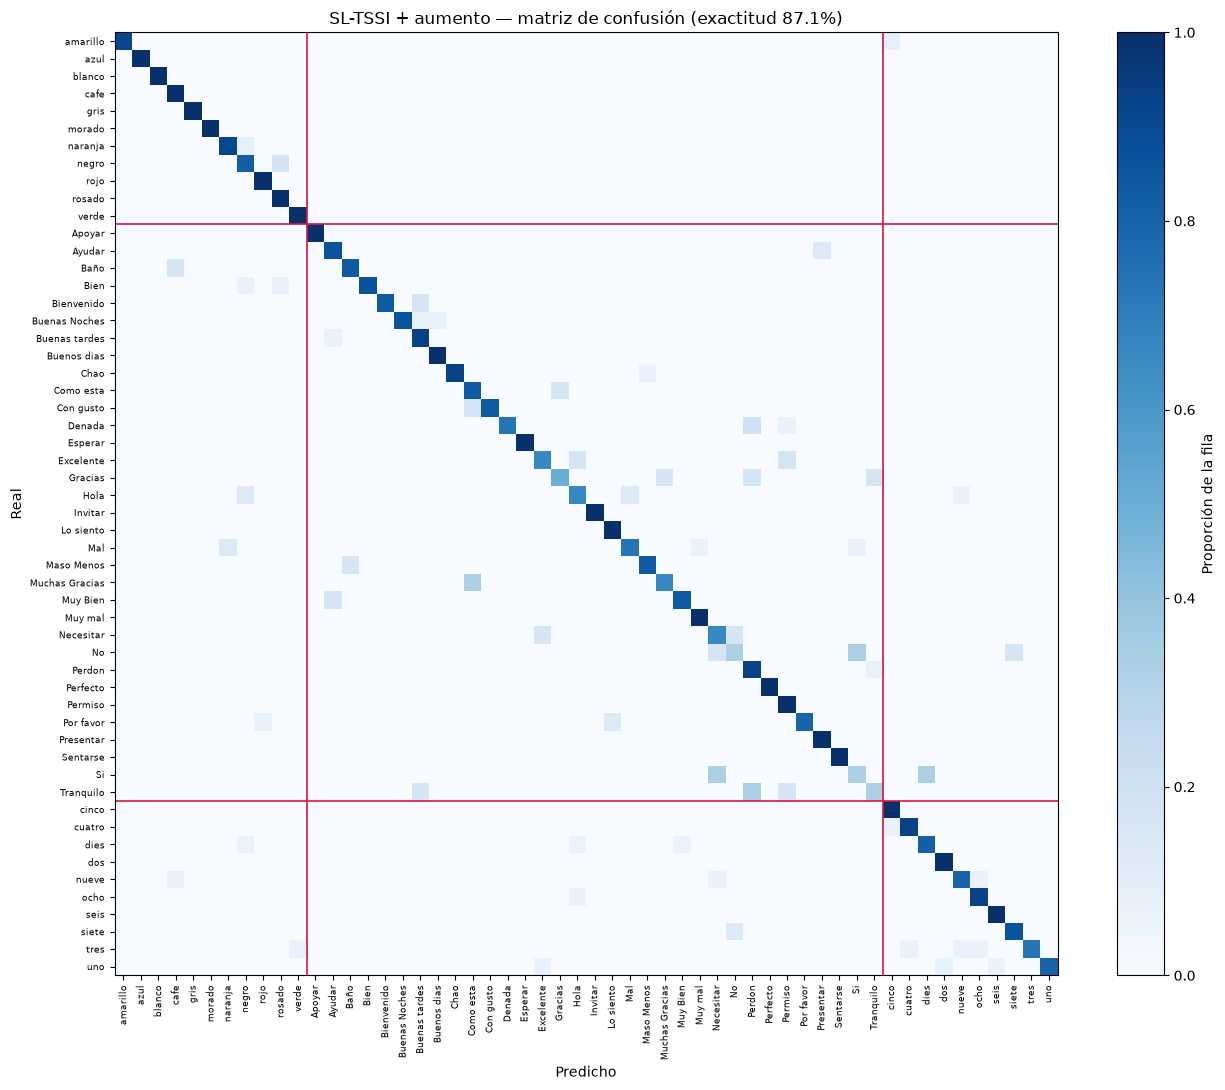

Los bloques rojos separan colores, cortesía y números. La diagonal fuerte es
lo que se busca; las manchas fuera de ella son las confusiones sistemáticas.


In [24]:
# Matriz de confusión completa, con las clases ordenadas por categoría.
ORDEN_CAT = ["Colores", "Cortesía", "Números"]
clases_ord = sorted(CLASES, key=lambda g: (ORDEN_CAT.index(grupo[g]), g))
pos = {g: i for i, g in enumerate(clases_ord)}

M = np.zeros((len(clases_ord), len(clases_ord)))
for real, pred in zip(reales_str, pred_aug_str):
    M[pos[real], pos[pred]] += 1
M_norm = M / np.maximum(M.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(M_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(clases_ord)))
ax.set_yticks(range(len(clases_ord)))
ax.set_xticklabels(clases_ord, rotation=90, fontsize=6.5)
ax.set_yticklabels(clases_ord, fontsize=6.5)
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
ax.set_title(f"SL-TSSI + aumento — matriz de confusión (exactitud {M.diagonal().sum() / M.sum():.1%})")

limites, acumulado = [], 0
for cat in ORDEN_CAT[:-1]:
    acumulado += sum(1 for g in clases_ord if grupo[g] == cat)
    limites.append(acumulado - 0.5)
for lim in limites:
    ax.axhline(lim, color="crimson", lw=1.2)
    ax.axvline(lim, color="crimson", lw=1.2)

plt.colorbar(im, ax=ax, fraction=0.046, label="Proporción de la fila")
plt.tight_layout()
plt.show()

print("Los bloques rojos separan colores, cortesía y números. La diagonal fuerte es")
print("lo que se busca; las manchas fuera de ella son las confusiones sistemáticas.")

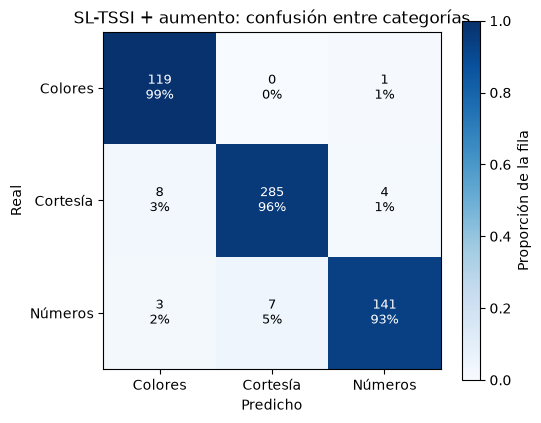

Cuando se equivoca, casi siempre lo hace dentro de la misma categoría.


In [25]:
# La misma matriz, resumida a las tres categorías.
matriz = np.zeros((3, 3), dtype=int)
for real, pred in zip(reales_str, pred_aug_str):
    matriz[ORDEN_CAT.index(grupo[real]), ORDEN_CAT.index(grupo[pred])] += 1

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(matriz / matriz.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(ORDEN_CAT)
ax.set_yticks(range(3)); ax.set_yticklabels(ORDEN_CAT)
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title("SL-TSSI + aumento: confusión entre categorías")
for i in range(3):
    for j in range(3):
        pct = matriz[i, j] / matriz[i].sum()
        ax.text(j, i, f"{matriz[i, j]}\n{pct:.0%}", ha="center", va="center",
                color="white" if pct > 0.5 else "black", fontsize=9)
plt.colorbar(im, ax=ax, label="Proporción de la fila")
plt.tight_layout()
plt.show()

print("Cuando se equivoca, casi siempre lo hace dentro de la misma categoría.")

## El modelo en funcionamiento

Tres videos del conjunto de prueba, uno por categoría, hechos por personas que el modelo
nunca vio.

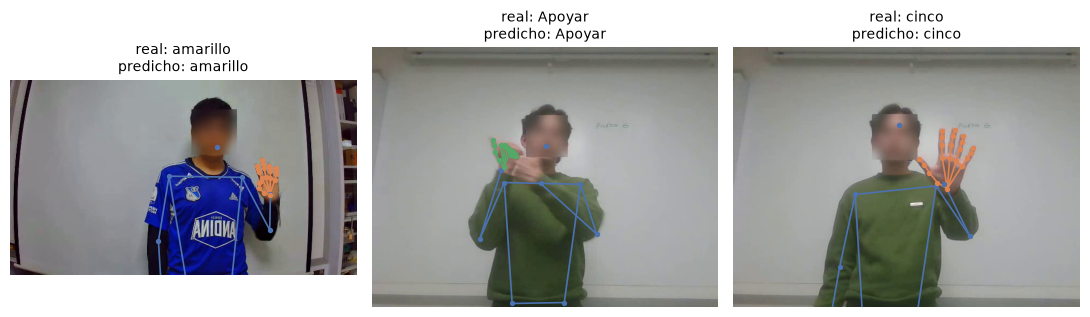

VIDEO      : Videos Colors/12/Colores/amarillo/1.avi
  señalante: 12  ·  30 fotogramas
  real     : amarillo
  predicho : amarillo

VIDEO      : Videos Courtesy/21/Cordialidad/Apoyar/0.avi
  señalante: 21  ·  67 fotogramas
  real     : Apoyar
  predicho : Apoyar

VIDEO      : Videos Numbers/21/Numeros/cinco/0.avi
  señalante: 21  ·  29 fotogramas
  real     : cinco
  predicho : cinco



In [26]:
ejemplos_demo = []
for cat in ORDEN_CAT:
    for i, e in enumerate(test_raw):
        if grupo[e["gloss"]] == cat:
            ejemplos_demo.append((i, e))
            break

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, (i, e) in zip(axes, ejemplos_demo):
    predicha = pred_aug_str[i]
    t = e["sign"].shape[0] // 2
    dibujar_esqueleto(ax, e["sign"][t].numpy(), fondo=leer_fotograma(e["name"], t))
    ax.set_title(f"real: {e['gloss']}\npredicho: {predicha}", fontsize=10,
                 color="black" if predicha == e["gloss"] else "crimson")
plt.tight_layout()
plt.show()

for i, e in ejemplos_demo:
    print(f"VIDEO      : {e['name']}")
    print(f"  señalante: {e['signer']}  ·  {e['sign'].shape[0]} fotogramas")
    print(f"  real     : {e['gloss']}")
    print(f"  predicho : {pred_aug_str[i]}")
    print()

---
# 7. Conclusiones

**Normalizar las coordenadas fue la mejora más importante.** Centrar el cuerpo en los
hombros y cada mano en su muñeca hace que el modelo vea la *forma* de la mano y no dónde
está la persona en la imagen. Con el mismo modelo y los mismos datos, la LSTM pasó de
25,4 % a 50,0 % y el Transformer de 51,2 % a 65,1 %.

**La imagen TSSI funciona.** Convertir la secuencia en imagen y usar una DenseNet
preentrenada da el mejor resultado del proyecto, con tres veces menos parámetros que el
Transformer. Que el preentrenamiento de ImageNet sirva para imágenes que no son fotos es
el punto interesante del artículo de Laines et al., y aquí se confirmó.

**El aumento de datos suma, con cautela.** Generar en cada época una variante distinta de
cada video (girada, estirada, con otro ritmo, con ruido o sin una mano en algunos
fotogramas) subió la exactitud en prueba de 84,7 % a **87,1 %** y el F1 macro de 82,0 % a
**85,2 %**, con el mismo modelo y el mismo costo al predecir. Donde más se nota es en los
números (+6,6 puntos) y en las señas de cortesía con menos videos. Antes de elegir las
transformaciones medimos cuáles anula el propio pipeline: la normalización cancela trasladar
y escalar, y el redimensionado a 128×128 cancela un cambio de velocidad uniforme. La prueba
de McNemar da p = 0,076, así que con una sola corrida no se puede descartar que parte de la
mejora sea azar, aunque todas las métricas apuntan en la misma dirección.

**El problema es de clasificación, no de traducción.** signjoey fue diseñado para
traducir oraciones continuas. Aquí cada video es una sola seña y el texto de referencia
es la misma glosa en minúsculas, así que su decoder de traducción no aporta nada. Por eso
BLEU, CHRF y ROUGE no son métricas útiles en este proyecto: BLEU-4 vale 0 por
construcción, porque ninguna referencia tiene cuatro palabras.

**Los errores que quedan tienen causa conocida.** Ya no son de arquitectura sino de
desbalance y sobreajuste: las señas de cortesía con 14 videos de entrenamiento siguen
concentrando los fallos, y aun con aumento el modelo llega al 100 % en entrenamiento.

## Limitaciones

- **Cada modelo se entrenó una sola vez**, con una sola semilla. Las conclusiones
  generales son sólidas, pero las cifras exactas pueden variar algunos puntos. Por eso la
  mejora del aumento (2,5 puntos) no es concluyente.
- **El conjunto de prueba es pequeño:** 568 videos de 7 personas, con un margen
  aproximado de ±3–4 puntos. Los resultados por seña se basan en muy pocos videos
  (muchas tienen solo 6) y deben leerse como tendencias.
- **La validación es optimista:** el mejor modelo se elige mirando dev, así que dev
  siempre supera a test. Lo que se reporta son los resultados de test.
- **La comparación no es del todo pareja:** SL-TSSI parte de pesos preentrenados en
  ImageNet y los otros modelos se entrenaron desde cero.
- **Sobre los datos:** los números del señalante 34 están duplicados en dos carpetas
  (afecta solo a dev, no a test), y la división supone que el número de cada señalante
  identifica a la misma persona en todas las categorías. MediaPipe no siempre detecta
  las manos; esos fotogramas se rellenan con ceros.
- **El lado de la mano está ligado a la categoría.** En el dataset los colores se
  grabaron con la mano hacia un lado de la imagen y los números y la cortesía hacia el
  otro, y el modelo aprendió a usar ese lado como pista: la misma seña reflejada puede
  cambiar de clase. Se notó al preparar el demo en vivo, que por eso evalúa cada seña
  como se vio y reflejada y se queda con la respuesta más segura; en el conjunto de
  prueba eso sube la exactitud de 87,1 % a 90,1 %.
- **No hay traducción real:** el texto de referencia es la glosa en minúsculas.

## Trabajo futuro

- **Frenar más el sobreajuste.** El modelo con aumento todavía llega al 100 % en
  entrenamiento: se pueden ampliar los rangos de rotación y estiramiento, probar *mixup*
  entre videos y compensar el desbalance de cortesía con pesos por clase en la pérdida.
- **Repetir los entrenamientos con varias semillas** y reportar promedio y desviación. Es
  la forma de confirmar si los 2,5 puntos del aumento son reales.
- **Quitar la dependencia del lado de la mano**, por ejemplo entrenando con reflejo
  horizontal y revisando antes qué señas cambian de significado al reflejarse.
- **Mejorar las características:** rellenar los fotogramas sin mano con el último valor
  conocido en vez de con ceros.
- **Extender a frases** con traducciones reales al español. En ese escenario la
  arquitectura de traducción de signjoey sí tendría sentido.